# 🦋 Week 4 — Scoreboard 1: which classical model predicts a cycle it has never seen?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SwRI-IDEA-Lab/butterflai2/blob/main/weeks/week_04/04_scoreboard1.ipynb)

> Which classical model best predicts emergence on held-out cycles — and how would you know if the
> answer had been bought rather than earned?

Week 3 built one model and scored it on a cycle it had never seen: a latent magnetic belt, a buoyancy
threshold, one shared shape across eighteen wings, an amplitude each, and a clock fitted per hemicycle.
It ended at −25.4 nats per hemicycle-year held out, and it ended with a list of things it could not
settle. Three of them were questions about the *shape* of the model: should the time profile be a gamma?
should the belt width depend on amplitude, on latitude, or on neither? does the threshold earn its keep?

This week we answer questions like those the only way they can be answered — by running the comparison.
That turns out to need less new mathematics than Week 3 and more new discipline, because a comparison is
very easy to run and surprisingly hard to *read*.

The week has four stages, and the first one happens before you write any code:

1. *You bring a knob of your own.* This notebook ships a catalog of alternatives at four levels. In your
   tutor session you work out a fifth: one knob none of those levels controls, with the question it
   answers and the sign you expect. You implement it in Task 36 and it goes on the board beside ours.
2. *You explore one knob at a time*, choosing which experiments you want to run — the notebook ships no
   expected set — and pricing them before you run them.
3. *You combine what won and optimize jointly.* One-knob rows are how you learn which knob did what.
   They are almost never the best model, and the best model is what the class is competing on.
4. *You submit.* Your final model becomes a standard report that merges into a class scoreboard.

Two things keep that honest, and they are the two tasks most worth your time: a demonstration of three
concrete ways this week's headline number can be improved *without improving a single prediction*, and a
check that the winning model produces a butterfly diagram a solar physicist would accept.

Section 1 is given code with no tasks: Weeks 1 to 3 compressed. Tasks 32–43 are yours.

---
## How to work this notebook

Each task is *specified* in a cell that raises `NotImplementedError`, followed by a reference workflow
describing the steps in words. Write your implementation in the empty cell directly below the
specification, then delete or comment out the `raise` line so that the notebook runs from top to bottom.
Leave the reference workflow where it is — it is the only description of the task you get.

Before you implement anything, open a session with the tutor prompt in `vocal_prompt_week04.md`: paste
that file, then this whole notebook, then your first question. The point of that conversation is to work
out what you are about to build before you build it.

Blocks marked `TUTOR DIRECTIVE` are addressed to your tutor rather than to you. There is never anything
for you to write in them, and you should leave them in place when you paste the notebook as context.

```text
TUTOR DIRECTIVE — session opening.

The student has pasted this entire notebook as context. Nothing in it has been run: every task raises
NotImplementedError, each is followed by a reference workflow, and the empty cell beneath each task is
the student's own workspace, not an omission for you to fill in. This session happens before they
implement anything, and its purpose is the conversation they have about what they are going to build.

So: do not write their task code, and do not walk them through a reference workflow step by step. Four
further TUTOR DIRECTIVE blocks appear later, at Sections 3, 6, 7 and 8, and each names the destinations
the conversation has to reach at that point. Everything else in the notebook is material you may draw on.

This week's session has one required output: the student leaves it with a knob of their own, which the
notebook's catalog does not contain. Section 3's directive says how to run that. Do not propose the knob.

This week's targets are the terms set in bold in the notebook text, each bolded where it is first
introduced. The student has therefore read a definition of every one of them, and has almost certainly
used none of them in a sentence of their own. Treat them all as unused: having read a term here does
not put it on the table, and you still have to introduce it yourself before asking them to deploy it.

The student should be pasting their Week 03 HANDOFF after this prompt. If they do, carry its levels and
anchors forward per domain name; the domain names are unchanged from last week. If they do not, ask once
whether they have it, then proceed without it rather than pressing.
```

In [1]:
# ── ButterflAI 2.0 standard setup — run this first ─────────────────────────
import os, sys, random, subprocess
from pathlib import Path

REPO_URL = "https://github.com/SwRI-IDEA-Lab/butterflai2.git"

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    REPO = Path("/content/butterflai2")
    if REPO.exists():
        subprocess.run(["git", "-C", str(REPO), "pull", "--ff-only"], check=False)
    else:
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(REPO / "requirements.txt")], check=True)
else:
    # Local: walk up from the notebook's folder to the repository root.
    REPO = next((p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "legacy" / "butterflAI_model.py").exists()), None)
    if REPO is None:
        raise RuntimeError("Could not find the butterflai2 repository root. "
                           "Open this notebook from inside your clone.")

DATA = REPO / "data"
DERIVED = DATA / "derived"
DERIVED.mkdir(exist_ok=True)
LEGACY = REPO / "legacy"
sys.path.insert(0, str(LEGACY))   # enables: from butterflAI_model import ButterflAIModel

SEED = 42
random.seed(SEED)
import numpy as np
np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = torch.device("cuda" if torch.cuda.is_available()
                          else "mps" if torch.backends.mps.is_available() else "cpu")
except ImportError:
    DEVICE = "cpu"

print(f"🦋 ButterflAI 2.0 | {'Colab' if IN_COLAB else 'local'} | repo: {REPO} | device: {DEVICE}")

🦋 ButterflAI 2.0 | Colab | repo: /content/butterflai2 | device: cpu


In [2]:
# Everything else this notebook needs. Phase A is numpy and scipy; PyTorch arrives in Week 5.
import hashlib
import json
import re
import time
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid, cumulative_trapezoid
from scipy.optimize import minimize, minimize_scalar, least_squares
from scipy.stats import kstest

from butterflAI_model import ButterflAIModel, A_REF

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.titlesize": 11, "figure.titlesize": 12})

# ── Weeks 1 to 3, re-declared. Notebooks are self-contained. ──
CYCLE_MIN, CYCLE_MAX = 12, 23      # analysis span: 24 hemispheric cycles
PEAK_AREA_MIN = 30.0               # MSH — drops pores and the smallest groups
AMP_AREA_MIN = 50.0                # MSH — ButterflAI 1.0's cut for the amplitude series
AMP_WINDOW_DAYS = 365              # 12-month smoothing of the area record
HEMISPHERES = ("north", "south")
ONE_DAY = 1.0 / 365.25             # one day, in years — our time unit everywhere

S_A, S_B = -6.0, 11.0              # the observation window in s, in years. Fixed program-wide.
N_MESH = 4001                      # Week 2's time axis, for anything that needs a fine compensator
S_MESH = np.linspace(S_A, S_B, N_MESH)
WINDOW_YEARS = S_B - S_A

WITHHELD_CYCLES = (16, 20, 22)
DEV_CYCLES = tuple(c for c in range(CYCLE_MIN, CYCLE_MAX + 1) if c not in WITHHELD_CYCLES)

LAM_MAX = 60.0                     # degrees. The latitude domain is |lat| in [0, LAM_MAX].
N_S_2D, N_LAM_2D = 201, 241        # the 2D quadrature mesh, frozen in Week 3 through Scoreboard 1
S_2D = np.linspace(S_A, S_B, N_S_2D)
LAM_2D = np.linspace(0.0, LAM_MAX, N_LAM_2D)
MESH_2D = (S_2D, LAM_2D)
B_CRIT = 1.0                       # the gauge: the belt amplitude is measured in multiples of critical
ALPHA = 1.0                        # the emission exponent, fixed in Week 3
MU_REF = 15.0                      # degrees. The reference latitude that defines s = 0.

CACHE = DERIVED / "scoreboard1"    # one JSON per variant. The class's results accumulate here.
CACHE.mkdir(parents=True, exist_ok=True)

print(f"window s in [{S_A:+.1f}, {S_B:+.1f}] yr · domain |lat| in [0, {LAM_MAX:.0f}] deg · "
      f"mesh {N_S_2D} x {N_LAM_2D} · cache {CACHE.relative_to(REPO)}")

window s in [-6.0, +11.0] yr · domain |lat| in [0, 60] deg · mesh 201 x 241 · cache data/derived/scoreboard1


---
## 1 · Previously: the data, the clock, and the loss

*Given code — no tasks. Weeks 1 to 3 compressed. If you did them, skim and check the numbers match.*

Four decisions carry over unchanged. An *event* is a sunspot group's *first observation*. The analysis
set is cycles 12–23 with peak corrected area above 30 MSH, which gives 22,122 events over 24 hemispheric
cycles. *Cycles 16, 20 and 22 are withheld* — sealed for a single reveal at the end of the program —
leaving nine cycles, 18 hemispheric cycles and 16,611 events for everything below. And *exposure is
treated as complete*: the catalog has no observing-day record, a series rebuilt from the original logs
gives a mean observed fraction of about 0.99 for these cycles, so every rate here is roughly 1% low and
we do not correct for it.

The clock is rebuilt exactly as Week 3 built it, because without it there is no `s`: a pooled drift
track `mu(s) = 15° · exp(-s / mu_b)` with `mu_b` shared across hemicycles and one time shift per
hemicycle, fitted by least squares to that hemicycle's own events. `MU_REF` = 15° is held fixed, which is
the gauge choice that makes `s` = 0 mean the 15° crossing. Once a hemicycle is aligned, `s` is a standard
coordinate and nothing downstream refits it.

What is *not* carried over verbatim is the model assembly and the fitter. Week 3 wrote `belt_field`,
`intensity_2d`, `make_intensity` and `fit_pooled` with the gamma shape and the constant width baked in.
Section 3 rebuilds them so that any one piece can be swapped without touching the others, which is the
whole architecture of a scoreboard. The loss itself — `log L = Σ log Λ − ∫∫Λ` — does not change, and the
quadrature functions below are Week 3's unaltered.

In [3]:
# Given: the catalog, the emergence table, the analysis set and the development split.
CATALOG = DATA / "composite_sunspot_groups_daily_measurements_10_23.csv"
daily = pd.read_csv(CATALOG)


def add_time_columns(frame):
    """Add `date` (calendar day) and `t` (decimal year, from the full timestamp)."""
    stamp = pd.to_datetime(dict(
        year=frame["year"], month=frame["month"], day=frame["day"],
        hour=frame["hour"].fillna(12).astype(int),
        minute=frame["minute"].fillna(0).astype(int),
        second=frame["second"].fillna(0).astype(int),
    ))
    day_of_year = (stamp.dt.dayofyear - 1 + stamp.dt.hour / 24.0
                   + stamp.dt.minute / 1440.0 + stamp.dt.second / 86400.0)
    year_length = np.where(stamp.dt.is_leap_year, 366.0, 365.0)
    frame = frame.copy()
    frame["date"] = stamp.dt.normalize()
    frame["t"] = stamp.dt.year + day_of_year / year_length
    return frame


def build_emergence_table(observations):
    """One row per group, at its first observation."""
    ordered = observations.sort_values("t")
    first = ordered.drop_duplicates("uniqueID", keep="first").set_index("uniqueID")
    by_group = ordered.groupby("uniqueID")
    table = pd.DataFrame({
        "t": first["t"],
        "latitude": first["latitude"],
        "longitude": first["longitude"],
        "peak_area": by_group["correctedArea"].max(),
        "cycle": by_group["CYCLE"].first(),
    })
    table = table[table["cycle"].notna()].copy()
    table["cycle"] = table["cycle"].astype(int)
    table["hemisphere"] = np.where(table["latitude"] >= 0, "north", "south")
    table["abs_latitude"] = table["latitude"].abs()
    return table.reset_index()


def apply_analysis_set(table):
    """Keep cycles CYCLE_MIN..CYCLE_MAX above the area cut, and label each hemispheric cycle."""
    keep = (table["cycle"].between(CYCLE_MIN, CYCLE_MAX)
            & (table["peak_area"] > PEAK_AREA_MIN))
    sel = table[keep].copy()
    sel["hemicycle"] = sel["cycle"].astype(str) + sel["hemisphere"].str[0].str.upper()
    return sel.sort_values(["hemicycle", "t"]).reset_index(drop=True)


daily = add_time_columns(daily)
obs = daily[daily["uniqueID"].notna()].copy()

peak_rows = obs.loc[obs.groupby("uniqueID")["correctedArea"].idxmax()]
peak_rows = peak_rows[peak_rows["latitude"].notna() & peak_rows["CYCLE"].notna()]
groups10 = pd.DataFrame({
    "date": peak_rows["date"].to_numpy(),
    "t": peak_rows["t"].to_numpy(),
    "latitude": peak_rows["latitude"].to_numpy(),
    "peak_area": peak_rows["correctedArea"].to_numpy(),
    "cycle": peak_rows["CYCLE"].astype(int).to_numpy(),
})
groups10["hemisphere"] = np.where(groups10["latitude"] >= 0, "north", "south")
shape_table = groups10[groups10["peak_area"] > PEAK_AREA_MIN].copy()

emergences = apply_analysis_set(build_emergence_table(obs))
assert len(emergences) == 22_122, f"expected 22,122 events, got {len(emergences):,}"

dev = emergences[emergences["cycle"].isin(DEV_CYCLES)].copy().reset_index(drop=True)
DEV_HEMICYCLES = sorted(dev["hemicycle"].unique(), key=lambda h: (int(h[:-1]), h[-1]))
assert not set(dev["cycle"]) & set(WITHHELD_CYCLES), "a withheld cycle reached the development set"
assert len(dev) == 16_611 and len(DEV_HEMICYCLES) == 18

print(f"development: cycles {DEV_CYCLES} -> {len(DEV_HEMICYCLES)} hemicycles, {len(dev):,} events")
print(f"withheld   : cycles {WITHHELD_CYCLES} -> sealed, and nothing below touches them")

development: cycles (12, 13, 14, 15, 17, 18, 19, 21, 23) -> 18 hemicycles, 16,611 events
withheld   : cycles (16, 20, 22) -> sealed, and nothing below touches them


In [4]:
# Given: Week 1's amplitude recipe. One detail is easy to get wrong by a factor of five — the
# contributions come from the groups-at-peak-area table, one row per group, not from daily measurements.
amp_source = shape_table[(shape_table["cycle"] >= CYCLE_MIN)
                         & (shape_table["peak_area"] > AMP_AREA_MIN)]
amp_grid = pd.date_range(amp_source["date"].min(), amp_source["date"].max(), freq="D")

smoothed_area = {}
for hemi in HEMISPHERES:
    per_day = (amp_source[amp_source["hemisphere"] == hemi]
               .groupby("date")["peak_area"].sum()
               .reindex(amp_grid, fill_value=0.0))
    smoothed_area[hemi] = per_day.rolling(AMP_WINDOW_DAYS, center=True,
                                          min_periods=AMP_WINDOW_DAYS // 3).mean()

AREA_AMPLITUDE = {}
for cyc in DEV_CYCLES:
    cycle_dates = shape_table.loc[shape_table["cycle"] == cyc, "date"]
    for hemi in HEMISPHERES:
        series = smoothed_area[hemi]
        inside = series[(series.index >= cycle_dates.min())
                        & (series.index <= cycle_dates.max())].dropna()
        AREA_AMPLITUDE[f"{cyc}{hemi[0].upper()}"] = float(inside.max()) / A_REF

amplitudes = pd.Series(AREA_AMPLITUDE).loc[DEV_HEMICYCLES].rename("A")
assert 0.07 < amplitudes.min() and amplitudes.max() < 0.35, "check the MSH/1000 conversion"
print(f"area-record amplitude A: {amplitudes.min():.3f} to {amplitudes.max():.3f}")

area-record amplitude A: 0.079 to 0.315


In [5]:
# Given: Week 3's clock. This is mandatory — without it there is no `s`.
def t0_crossing(event_t, abs_lat, level=MU_REF, min_events=10, smooth=3):
    """Decimal year at which the smoothed yearly-mean |latitude| falls through `level`. A starting value."""
    frame = pd.DataFrame({"year": np.floor(np.asarray(event_t, dtype=float)).astype(int),
                          "abs_lat": np.asarray(abs_lat, dtype=float)})
    yearly = frame.groupby("year")["abs_lat"].agg(["mean", "count"])
    yearly = yearly[yearly["count"] >= min_events]
    t_mid = yearly.index.to_numpy() + 0.5
    curve = (pd.Series(yearly["mean"].to_numpy())
             .rolling(smooth, center=True, min_periods=1).mean().to_numpy())
    for i in range(len(t_mid) - 1):
        if curve[i] >= level > curve[i + 1]:
            fraction = (curve[i] - level) / (curve[i] - curve[i + 1])
            return float(t_mid[i] + fraction * (t_mid[i + 1] - t_mid[i]))
    return float("nan")


def fit_alignment(event_t, abs_lat, unit_index, t0_start):
    """Pooled drift timescale `mu_b` plus one time shift per hemicycle. This is what defines `s`."""
    unit_index = np.asarray(unit_index, dtype=int)
    t_relative = np.asarray(event_t, dtype=float) - np.asarray(t0_start, dtype=float)[unit_index]
    lat = np.asarray(abs_lat, dtype=float)
    n_units = len(t0_start)

    def residual(p):
        mu_b = np.exp(p[0])
        return MU_REF * np.exp(-(t_relative - p[1:][unit_index]) / mu_b) - lat

    start = np.concatenate([[np.log(8.0)], np.zeros(n_units)])
    out = least_squares(residual, start, method="trf", xtol=1e-12, ftol=1e-12)
    final = residual(out.x)
    variance = float(final @ final) / (len(final) - len(out.x))
    _, singular, vt = np.linalg.svd(out.jac, full_matrices=False)
    errors = np.sqrt(np.diag((vt.T / singular ** 2) @ vt * variance))
    return dict(mu_b=float(np.exp(out.x[0])), mu_b_se=float(errors[0] * np.exp(out.x[0])),
                delta=out.x[1:].copy(), delta_se=errors[1:].copy(),
                resid_rms=float(np.sqrt(np.mean(final ** 2))))


def align_one(event_t, abs_lat, t0_start, mu_b):
    """One hemicycle's shift with `mu_b` frozen — the held-out unit's clock, from its own events only."""
    t_relative = np.asarray(event_t, dtype=float) - t0_start
    lat = np.asarray(abs_lat, dtype=float)

    def residual(p):
        return MU_REF * np.exp(-(t_relative - p[0]) / mu_b) - lat

    return float(least_squares(residual, np.zeros(1), method="trf", xtol=1e-12, ftol=1e-12).x[0])


T0_START = {h: t0_crossing(g["t"].to_numpy(), g["abs_latitude"].to_numpy())
            for h, g in dev.groupby("hemicycle")}
assert not any(np.isnan(v) for v in T0_START.values())

UNIT_OF = {h: j for j, h in enumerate(DEV_HEMICYCLES)}
t0_start_array = np.array([T0_START[h] for h in DEV_HEMICYCLES])
alignment = fit_alignment(dev["t"].to_numpy(), dev["abs_latitude"].to_numpy(),
                          dev["hemicycle"].map(UNIT_OF).to_numpy(), t0_start_array)

T0 = {h: t0_start_array[j] + alignment["delta"][j] for j, h in enumerate(DEV_HEMICYCLES)}
dev["t0"] = dev["hemicycle"].map(T0)
dev["s"] = dev["t"] - dev["t0"]
assert dev["s"].min() > S_A and dev["s"].max() < S_B, "the clock pushed an event out of the window"

EVENTS = {h: (g["abs_latitude"].to_numpy(), g["s"].to_numpy()) for h, g in dev.groupby("hemicycle")}
RAW_EVENTS = {h: (g["abs_latitude"].to_numpy(), g["t"].to_numpy()) for h, g in dev.groupby("hemicycle")}
COUNTS = {h: len(EVENTS[h][0]) for h in DEV_HEMICYCLES}
CYCLE_UNITS = {c: [h for h in DEV_HEMICYCLES if int(h[:-1]) == c] for c in DEV_CYCLES}

print(f"shared drift timescale mu_b = {alignment['mu_b']:.3f} +/- {alignment['mu_b_se']:.3f} yr "
      f"(Week 3: 8.024 +/- 0.109)")
print(f"s spans {dev['s'].min():+.3f} to {dev['s'].max():+.3f} · events per hemicycle "
      f"{min(COUNTS.values())} to {max(COUNTS.values())}")

shared drift timescale mu_b = 8.024 +/- 0.109 yr (Week 3: 8.024 +/- 0.109)
s spans -5.286 to +7.815 · events per hemicycle 525 to 1590


In [6]:
# Given: the loss, unchanged all program long, and Week 2's time-rescaling machinery.
def softplus(x):
    with np.errstate(invalid="ignore"):
        return np.logaddexp(0.0, np.asarray(x, dtype=float))


def integrate_2d(values, mesh=MESH_2D):
    """Double trapezoid integral of `values`, laid out as (latitude, time), over the mesh."""
    s_mesh, lam_mesh = mesh
    return float(trapezoid(trapezoid(values, lam_mesh, axis=0), s_mesh))


def log_likelihood_2d(event_lat, event_s, intensity_fn, mesh=MESH_2D):
    """log L = sum_i log Lambda(|lat_i|, s_i) - double integral of Lambda over the mesh."""
    s_mesh, lam_mesh = mesh
    at_events = np.asarray(intensity_fn(np.asarray(event_lat, dtype=float),
                                        np.asarray(event_s, dtype=float)), dtype=float)
    if not np.all(np.isfinite(at_events)) or np.any(at_events <= 0.0):
        return -np.inf
    on_mesh = intensity_fn(lam_mesh[:, None], s_mesh[None, :])
    total = float(np.sum(np.log(at_events)) - integrate_2d(on_mesh, mesh))
    return total if np.isfinite(total) else -np.inf


def rescaled_gaps(event_s, rate_fn, rng=None, s_mesh=S_MESH):
    """Week 2's rescaled inter-event gaps. Under a correct rate they are iid Exp(1).

    `rng` breaks the catalog's whole-day ties by jittering each event inside its own day. The tie policy
    is stated rather than silently applied, and every model this week gets the identical jitter draw.
    """
    event_s = np.sort(np.asarray(event_s, dtype=float))
    if rng is not None:
        event_s = np.sort(event_s + rng.uniform(0.0, ONE_DAY, len(event_s)))
    rate_on_mesh = np.asarray(rate_fn(s_mesh), dtype=float)
    compensator = np.concatenate([[0.0], cumulative_trapezoid(rate_on_mesh, s_mesh)])
    return np.diff(np.concatenate([[0.0], np.interp(event_s, s_mesh, compensator)]))


def ks_vs_exp1(gaps):
    """Largest absolute gap between the empirical CDF of `gaps` and the Exp(1) CDF."""
    sorted_gaps = np.sort(np.asarray(gaps, dtype=float))
    n = len(sorted_gaps)
    model_cdf = 1.0 - np.exp(-sorted_gaps)
    above = np.arange(1, n + 1) / n - model_cdf
    below = model_cdf - np.arange(0, n) / n
    return float(np.max(np.maximum(above, below)))


model_10 = ButterflAIModel()
print("carried forward: log_likelihood_2d · integrate_2d · softplus · rescaled_gaps · ks_vs_exp1")

carried forward: log_likelihood_2d · integrate_2d · softplus · rescaled_gaps · ks_vs_exp1


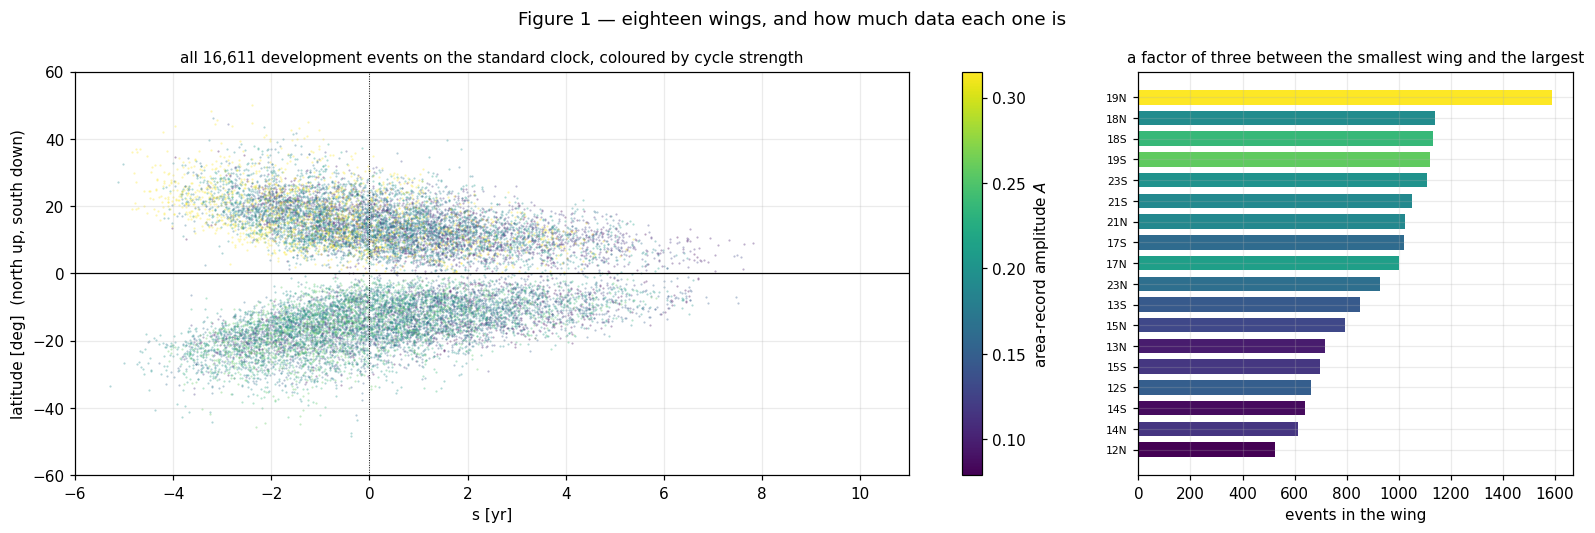

In [7]:
# Given: Figure 1 — the data, before any of it is modelled. Everything this week does is an attempt to
# describe this picture with a handful of numbers, so it is worth looking at first.
AMP_SERIES = pd.Series(AREA_AMPLITUDE).loc[DEV_HEMICYCLES]
AMP_NORM = plt.Normalize(AMP_SERIES.min(), AMP_SERIES.max())
AMP_CMAP = plt.cm.viridis


def amplitude_colour(label):
    """One wing's colour, fixed by its area-record amplitude. Used by every figure in this notebook."""
    return AMP_CMAP(AMP_NORM(AREA_AMPLITUDE[label]))


fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.9), gridspec_kw=dict(width_ratios=[2.4, 1.0]))

ax = axes[0]
for label in DEV_HEMICYCLES:
    lat, s_here = EVENTS[label]
    sign = 1.0 if label.endswith("N") else -1.0
    ax.scatter(s_here, sign * lat, s=2.0, color=amplitude_colour(label), alpha=0.35, linewidths=0)
ax.axhline(0.0, color="k", lw=0.8)
ax.axvline(0.0, color="k", lw=0.6, ls=":")
ax.set_xlim(S_A, S_B)
ax.set_ylim(-LAM_MAX, LAM_MAX)
ax.set_xlabel("s [yr]")
ax.set_ylabel("latitude [deg]  (north up, south down)")
ax.set_title(f"all {len(dev):,} development events on the standard clock, "
             f"coloured by cycle strength", fontsize=10)
plt.colorbar(plt.cm.ScalarMappable(norm=AMP_NORM, cmap=AMP_CMAP), ax=ax,
             label="area-record amplitude $A$")

ax = axes[1]
by_size = sorted(DEV_HEMICYCLES, key=lambda h: COUNTS[h])
ax.barh(np.arange(len(by_size)), [COUNTS[h] for h in by_size],
        color=[amplitude_colour(h) for h in by_size], height=0.7)
ax.set_yticks(np.arange(len(by_size)))
ax.set_yticklabels(by_size, fontsize=7)
ax.set_xlabel("events in the wing")
ax.set_title("a factor of three between the smallest wing and the largest", fontsize=10)
fig.suptitle("Figure 1 — eighteen wings, and how much data each one is")
plt.tight_layout()
plt.show()

---
## 2 · What a scoreboard is

A **leaderboard** is a table of models scored the same way on the same held-out data, ordered by that
score. It is the simplest useful object in empirical modelling and it is also the easiest to misread, so
this section fixes five things before any of it is built.

### Two kinds of row, answering two different questions

An **ablation** is a variant that differs from a reference model in exactly *one* knob. Its score answers
*which knob did it* — because everything else is held fixed, the difference in score is attributable to
that knob and to nothing else. Change two knobs at once and you have a perfectly good model whose score
tells you nothing about either knob.

A *candidate* changes as many knobs as it likes. Its score answers a different and equally real question:
*what is the best model we have*. Candidates are what the class competes on, and the best model will
almost certainly be a candidate rather than a one-knob row — knobs interact, and the combination of two
improvements is rarely the sum of them.

Both kinds go in the same table. Neither kind answers the other's question, so they are ranked separately
and the table says which is which.

### Two metrics, because one of them is blind

*The headline metric is the held-out log-likelihood*, in nats per hemicycle-year, with the amplitude of
each held-out wing predicted from the sunspot-area record. It sees everything the model claims: how many
groups appear, when, and at what latitude.

*The second metric is the time-rescaling KS statistic against Exp(1)*, from Week 2. To compute it for a
two-dimensional model we need a rate in time alone, which is the **marginal intensity** — the intensity
integrated over the latitude domain, `λ(s) = ∫ Λ(|λ|, s) dλ`, in events per year. The KS statistic
therefore sees *only the times*. It cannot tell a good latitude model from a bad one, and it carries no
units, which is why it is the one statistic in this program that is comparable between a 1D and a 2D
model.

Keep both and report them side by side. A knob that moves one and not the other is telling you where it
acts, and that is information a single combined number would destroy. Never average them.

### Scoring on data you fitted tells you the wrong thing

A model with more knobs always fits the data it was fitted to better. We call that **overfitting** when
the improvement does not survive contact with data the model has never seen: the extra freedom went into
describing this particular sample rather than the process behind it. The opposite is **generalization**,
and it is the only thing we are trying to buy — performance on a replication unit that took no part in
the fit. That is why every number in the leaderboard column comes from leave-one-cycle-out, and why
the in-sample score is kept in the table only as a contrast.

### What the held-out unit is allowed to contribute to its own score

This is the protocol, and it is the part students get wrong. Week 3 settled it:

| quantity | where it comes from for a held-out hemicycle |
|---|---|
| the clock (`s`) | *its own events*, with the shared drift timescale taken from the training fold |
| the belt amplitude | the *area record*, through a map fitted on the training wings |
| every shape parameter | the *training* fold, and nothing else |

The first row is a PI decision and it bounds the claim: the score says the model predicts the *shape* of
a wing it has never seen, on a clock standardized from that wing's own events. It is not a forecast of
when a cycle will happen. The second row is a genuine prediction, because the area record is an
independent observable. The third row is the line that must not be crossed — a shape parameter fitted on
the held-out wing makes the result a *bound* on what the shape could do, not a prediction, and this
notebook reports such rows unranked rather than pretending they compete.

### What makes two rows comparable at all

A score in nats per hemicycle-year depends on the mesh, the latitude domain, the time window, the set of
folds and the amplitude source. All five are frozen, and Section 4 hashes them into a *protocol
fingerprint* that travels with every result. Two rows with different fingerprints are not two models —
they are two rulers, and comparing them is **metric gaming**: improving a reported number without
improving a single prediction. Section 7 measures three ways to do it, because the only defence against
gaming a metric is knowing exactly how much it can be gamed by.

One consequence worth stating. Week 2's one-dimensional models cannot appear on this board: a likelihood
over times alone and a likelihood over times and latitudes have different units, so they do not belong in
one column. Nor can a negative binomial model of *binned counts* — its likelihood is over counts in bins,
not over event times, and no choice of bin makes the two numbers the same quantity. Both are legitimate
models, scored on different quantities, and the honest move is to leave them off rather than to coerce
them on.

### Forty people, nine folds

Finally, the thing that makes this week's competition interesting and slightly dangerous. Choosing among
many candidate models by comparing their scores is **model selection**, and the score of the *winner* of
a large selection is optimistic, because some of what won was luck on these particular nine folds.
With a class of forty each running several variants, the development leaderboard is a provisional
ordering, not a verdict. That is exactly why three cycles were sealed in Week 2 and have not been touched
since.

---
## 3 · The knob catalog: four levels, and the one you bring

Week 3's model was written as one block of code with a gamma profile and a constant width baked into it.
To compare alternatives we have to take it apart, so that the fitter never knows which variant it is
running. The model is a product of *stages*:

```
B(|lat|, s) = a_hc · g(s) · profile(|lat| − mu(s), w) · gate(...)
Lambda      = emission(B)
```

and each stage is a *library*: a dictionary of named values, each with the same signature, each declaring
its own parameters. A *spec* is then nothing but a choice of one value per stage —

```python
dict(shape="gamma", pooling="shared", drift="exponential", profile="gaussian",
     width="constant", gate="none", emission="threshold")      # this is Week 3's model
```

— and a variant's name is generated from the spec, so a row on the leaderboard can always be traced back
to the exact knob settings that produced it.

Four of the stages ship with several values, and those are the four levels of this week's menu:

| level | stage | question it asks |
|---|---|---|
| L1 | `shape` | what is the time profile `g(s)` of a wing? |
| L2 | `pooling` | which parameters are shared across wings, and which belong to one wing? |
| L3 | `width` | what sets the latitudinal thickness of the belt? |
| L4 | `emission` | does a buoyancy threshold earn its keep? |

Three stages — `drift`, `profile` and `gate` — ship with exactly *one* value each. *A stage with one value
is not a knob*: there is nothing to vary, so it cannot appear in a comparison. Turning one of them into a
knob, by adding a second value, is Task 36 and it is the one you bring from your tutor session.

Returning students: the levels escalate, and L3 is where the interesting ones start. `LEVELS` below is
only a reminder of the order — nothing in the notebook forces you through it.

In [8]:
# Given: the bookkeeping that lets every library declare its own parameters.
#
# A fitted parameter that must stay positive is optimized as its logarithm; a shape parameter that must
# exceed 1 is optimized as log(k - 1), exactly as in Weeks 2 and 3; anything that may take either sign is
# optimized directly. Each library entry names the transform for each of its parameters, and the fitter
# reads it off rather than knowing anything about the model.
LEVELS = {1: "shape", 2: "pooling", 3: "width", 4: "emission", 5: "the stage you turn into a knob"}


def to_nat(z, kind):
    """Unconstrained real -> the parameter the model uses."""
    if kind == "log":
        return float(np.exp(z))
    if kind == "logm1":
        return 1.0 + float(np.exp(z))
    return float(z)


def to_unc(v, kind):
    """The parameter the model uses -> an unconstrained real."""
    if kind == "log":
        return float(np.log(v))
    if kind == "logm1":
        return float(np.log(max(v - 1.0, 1e-6)))
    return float(v)


print("transforms: log (positive) · logm1 (greater than one) · real (either sign)")

transforms: log (positive) · logm1 (greater than one) · real (either sign)


### L1 · the time profile

`g(s)` says how a wing grows and collapses. Week 3 used a gamma profile with its onset pinned at the
window start, chosen in Week 2 because it looked like the data — which is a reason to *try* it, not a
reason to keep it.

Every family here is normalized to *peak 1*, and that is not cosmetic. It makes `a_hc` the peak field
strength in multiples of critical, so the thinning bound `max Λ = emission(a_hc)` stays exact and
analytic whatever family you plug in. A family that is not normalized this way would silently break
Section 8's simulation.

In [ ]:
# raise NotImplementedError("Task 32: L1 — a library of time profiles, each normalized to peak 1")
# Reference workflow:
#   1. Write one function per family, each with the signature `fn(x, p)`, where `x = s - S_A` is years
#      since the window start and `p` is that family's parameter tuple. Return 0 wherever `x` is negative.
#   2. Normalize every one of them to peak 1 — divide the profile by its own maximum *analytically*, by
#      writing it in terms of the location of its peak, rather than numerically. For the gamma that peak is
#      at `(k-1)*theta`; for the Weibull at `lambda*((k-1)/k)**(1/k)`; for the others it is a parameter.
#   3. Give each family at least a rise and a decay that can differ, except the deliberate control: one
#      symmetric family, so that the leaderboard can be seen rejecting something.
#   4. Collect them in a dict `SHAPES` keyed by name. Each entry needs `fn`, a `transform` tuple naming
#      the transform of each parameter, a `start` tuple of sensible initial values in natural units, a
#      `names` tuple for printing, and `rise`: the index of the parameter that controls the *rise*, which
#      L2 needs in order to free it per wing.
#   5. Write `draw_shape(ax, name, params=None, **style)`, which plots one family on an axis it is handed
#      and labels that axis. It must not create a figure and must not call `plt.show()` — later cells
#      compose several of these into one figure, and a primitive that opens its own figure cannot be
#      composed. Every drawing function in this notebook follows that rule.
#   Five families is a good number. `gamma` must be one of them, with Week 3's parameterization.

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Define the five analytical families, each normalized to peak 1 ---

def _shape_gamma(x, p):
    # p = (k, theta)
    # Gamma PDF: x**(k-1) * exp(-x/theta)
    # Peak is at x_peak = (k - 1) * theta (for k > 1)
    k, theta = p
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x)
    mask = x > 0
    if k <= 1:
        return out  # gamma requires k > 1 for analytical peak
    x_peak = (k - 1.0) * theta
    max_val = (x_peak ** (k - 1.0)) * np.exp(-x_peak / theta)
    out[mask] = (x[mask] ** (k - 1.0)) * np.exp(-x[mask] / theta) / max_val
    return out

def _shape_weibull(x, p):
    # p = (k, scale)
    # Weibull: (x/scale)**(k-1) * exp(-(x/scale)**k)
    # Peak at x_peak = scale * ((k-1)/k)**(1/k) (for k > 1)
    k, scale = p
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x)
    mask = x > 0
    if k <= 1:
        return out
    x_peak = scale * ((k - 1.0) / k) ** (1.0 / k)
    max_val = ((x_peak / scale) ** (k - 1.0)) * np.exp(-(x_peak / scale) ** k)
    out[mask] = ((x[mask] / scale) ** (k - 1.0)) * np.exp(-(x[mask] / scale) ** k) / max_val
    return out

def _shape_lognormal(x, p):
    # p = (mu, sigma)
    # Lognormal mode (peak) is at exp(mu - sigma**2)
    mu, sigma = p
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x)
    mask = x > 0
    x_peak = np.exp(mu - sigma ** 2)
    max_val = (1.0 / x_peak) * np.exp(-(np.log(x_peak) - mu) ** 2 / (2.0 * sigma ** 2))
    out[mask] = (1.0 / x[mask]) * np.exp(-(np.log(x[mask]) - mu) ** 2 / (2.0 * sigma ** 2)) / max_val
    return out

def _shape_symmetric_gaussian(x, p):
    # p = (peak_loc, width)
    # Symmetric control: exp(-(x-peak_loc)**2 / (2*width**2))
    # Peak is at peak_loc, value is 1 there analytically
    peak_loc, width = p
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x)
    mask = x > 0
    out[mask] = np.exp(-(x[mask] - peak_loc) ** 2 / (2.0 * width ** 2))
    return out

def _shape_two_sided_exp(x, p):
    # p = (peak_loc, rise, decay)
    # Two-sided exponential: exp((x-peak_loc)/rise) for x < peak_loc
    # exp(-(x-peak_loc)/decay) for x >= peak_loc
    peak_loc, rise, decay = p
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x)
    mask = x > 0
    xm = x[mask]
    out[mask] = np.where(xm < peak_loc,
                         np.exp((xm - peak_loc) / rise),
                         np.exp(-(xm - peak_loc) / decay))
    return out

# --- 2. Collect in SHAPES dictionary ---
SHAPES = {
    "gamma": {
        "fn": _shape_gamma,
        "transform": ("logm1", "log"),
        "start": (3.0, 1.5),
        "names": ("k", "theta"),
        "rise": 0
    },
    "weibull": {
        "fn": _shape_weibull,
        "transform": ("logm1", "log"),
        "start": (2.5, 3.5),
        "names": ("k", "scale"),
        "rise": 0
    },
    "lognormal": {
        "fn": _shape_lognormal,
        "transform": ("real", "log"),
        "start": (1.2, 0.6),
        "names": ("mu", "sigma"),
        "rise": 1
    },
    "symmetric_gaussian": {
        "fn": _shape_symmetric_gaussian,
        "transform": ("log", "log"),
        "start": (3.0, 2.0),
        "names": ("peak_loc", "width"),
        "rise": 1
    },
    "two_sided_exp": {
        "fn": _shape_two_sided_exp,
        "transform": ("log", "log", "log"),
        "start": (3.0, 1.0, 2.5),
        "names": ("peak_loc", "rise", "decay"),
        "rise": 1
    }
}

# --- 3. Draw shape plotting function ---
def draw_shape(ax, name, params=None, **style):
    if params is None:
        params = SHAPES[name]["start"]
    x_plot = np.linspace(0.0, S_B - S_A, 500)
    y_plot = SHAPES[name]["fn"](x_plot, params)
    ax.plot(x_plot, y_plot, **style)
    ax.set_xlabel("Years since window start (s - S_A)")
    ax.set_ylabel("Time profile (Peak = 1)")


In [11]:
# Given: check the normalization before trusting any of it. A family whose peak is not 1 breaks the
# thinning bound in Section 8, and it breaks it silently.
x_check = np.linspace(0.0, S_B - S_A, 20001)
for name, entry in SHAPES.items():
    # Evaluate on the grid, but also explicitly include the analytical peak location to avoid grid-mismatch errors
    start_params = entry["start"]
    if name == "two_sided_exp":
        peak_x = start_params[0]
    elif name == "symmetric_gaussian":
        peak_x = start_params[0]
    elif name == "lognormal":
        peak_x = np.exp(start_params[0] - start_params[1]**2)
    elif name == "weibull":
        k, scale = start_params
        peak_x = scale * ((k - 1.0) / k) ** (1.0 / k) if k > 1 else 0.0
    elif name == "gamma":
        k, theta = start_params
        peak_x = (k - 1.0) * theta if k > 1 else 0.0
    else:
        peak_x = 0.0

    eval_pts = np.unique(np.concatenate([x_check, [peak_x]]))
    peak = float(np.max(entry["fn"](eval_pts, start_params)))
    print(f"   {name:10s} {len(entry['start'])} parameters  peak = {peak:.6f}  "
          f"{'OK' if abs(peak - 1.0) < 1e-6 else 'NOT NORMALIZED'}")
    assert abs(peak - 1.0) < 1e-6, f"{name} does not peak at 1"

   gamma      2 parameters  peak = 1.000000  OK
   weibull    2 parameters  peak = 1.000000  OK
   lognormal  2 parameters  peak = 1.000000  OK
   symmetric_gaussian 2 parameters  peak = 1.000000  OK
   two_sided_exp 3 parameters  peak = 1.000000  OK


### L2 · pooling

Week 3 shared every shape parameter across all 18 wings and gave each wing one amplitude. That was a
choice with a reason — one event in a thousand lands on the rising edge of a wing, so a single hemicycle
cannot determine the shape it is drawn from — but it is still a choice, and there are others.

This stage partitions the shape parameters three ways:

- *shared*: one value for all 18 wings, as in Week 3.
- *per hemisphere*: one value for the nine northern wings and another for the nine southern ones. This
  asks a physical question — the two hemispheres of a cycle are known to differ in amplitude and in
  timing, which is **hemispheric asymmetry**, and this variant asks whether they also differ in the
  *shape* of a wing rather than only in its size.
- *per wing*: every hemicycle gets its own value.

The third one has a consequence you have to follow through. If a shape parameter is fitted per wing, then
a wing the model has never seen *has no value for it* — and the only place to get one is that wing's own
events. That is the line Section 2's protocol draws: such a row is a bound on what the shape could
achieve, not a prediction, and the runner must mark it so that the leaderboard never ranks it against
rows that predicted honestly.

In [ ]:
raise NotImplementedError("Task 33: L2 — the pooling plans, and the flag that says a plan cannot predict")
# Reference workflow:
#   1. Write a dict `POOLINGS` keyed by plan name. Each entry holds `assign`, a function of the number of
#      shape parameters and the index of the rise parameter, returning a list of that length whose entries
#      are the strings "shared", "hemi" or "wing" — one per shape parameter.
#   2. Four plans: everything shared; everything per hemisphere; the rise parameter per wing with the rest
#      shared; and everything per wing. Give each a short `note` for printing.
#   3. Write `is_conditional(assignment)`, which returns True when any parameter is assigned per wing.
#      That single boolean is what later sections use to keep a bound out of the ranking, so it belongs
#      here with the plans rather than being re-derived wherever it is needed.
#   4. Write `draw_envelope(ax, event_s, width=0.5, **style)`: one wing's events binned in time and
#      normalized to peak 1, drawn on the axis it is handed. Normalizing is the point — you are about to
#      ask whether eighteen wings of very different sizes share one shape, and a raw count would answer
#      a different question.

In [12]:

# Put your code for Task 33 here
# --- 1. Define the POOLINGS dictionary holding the four assignment plans ---

def _pool_shared(n_shape, rise_idx):
    return ["shared"] * n_shape

def _pool_hemi(n_shape, rise_idx):
    return ["hemi"] * n_shape

def _pool_wing_rise(n_shape, rise_idx):
    return ["wing" if i == rise_idx else "shared" for i in range(n_shape)]

def _pool_wing(n_shape, rise_idx):
    return ["wing"] * n_shape

POOLINGS = {
    "shared": {
        "assign": _pool_shared,
        "note": "all shape parameters shared across all 18 wings"
    },
    "hemi": {
        "assign": _pool_hemi,
        "note": "shape parameters separate per hemisphere (N vs S)"
    },
    "wing_rise": {
        "assign": _pool_wing_rise,
        "note": "rise parameter separate per wing, others shared"
    },
    "wing": {
        "assign": _pool_wing,
        "note": "all shape parameters separate per wing (conditional bound)"
    }
}

# --- 2. Define the is_conditional check ---

def is_conditional(assignment):
    """Return True if any parameter is assigned to be fitted per wing."""
    return "wing" in assignment

# --- 3. Draw envelope function ---

def draw_envelope(ax, event_s, width=0.5, **style):
    """Plot a normalized binned envelope of the event arrivals in time to compare shapes."""
    event_s = np.asarray(event_s, dtype=float)
    bins = np.arange(S_A, S_B + width, width)
    counts, edges = np.histogram(event_s, bins=bins)

    # Peak normalize to 1
    max_count = counts.max() if counts.size > 0 and counts.max() > 0 else 1.0
    y = counts / max_count

    # Plot as step-like curves representing density envelopes
    centers = 0.5 * (edges[:-1] + edges[1:])
    ax.plot(centers - S_A, y, **style)
    ax.set_xlabel("Years since window start (s - S_A)")
    ax.set_ylabel("Envelope density (Peak = 1)")

In [ ]:
# Given: what each plan does to the parameter count, for a two-parameter family and for a three.
for plan, entry in POOLINGS.items():
    for family in ("gamma", "two_sided"):
        n = len(SHAPES[family]["start"])
        assignment = entry["assign"](n, SHAPES[family]["rise"])
        print(f"   {plan:11s} {family:10s} {assignment}"
              f"{'   <- conditional' if is_conditional(assignment) else ''}")

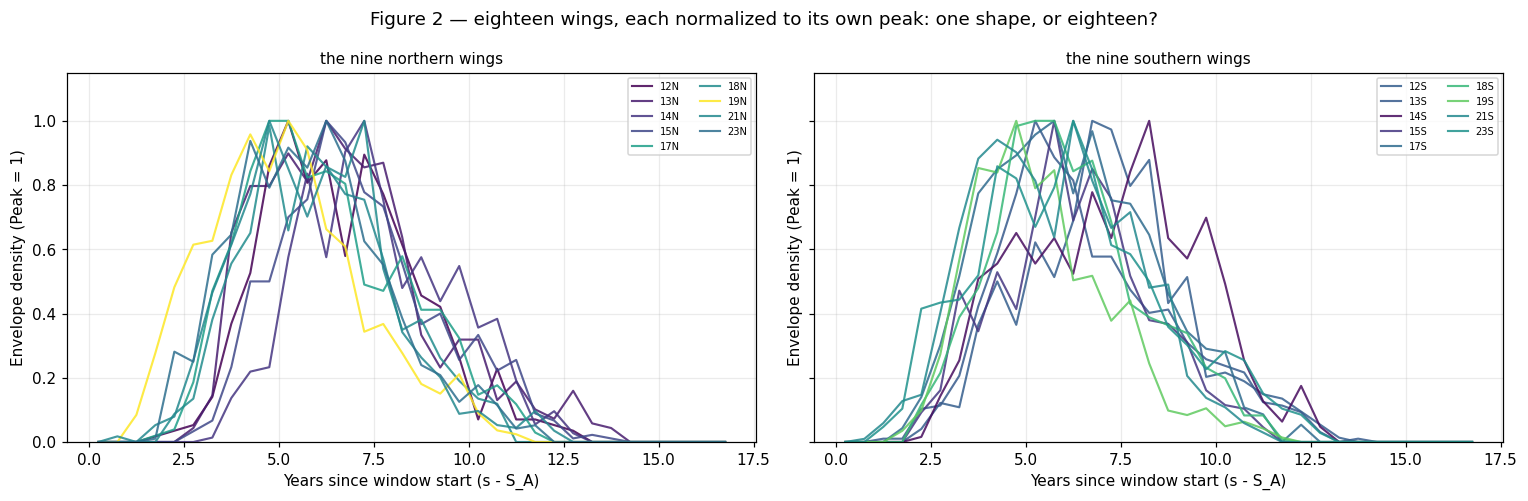

In [13]:
# Given: Figure 2 — the question L2 is really asking. The model is about to give all eighteen wings one
# shared time profile with nothing per wing but a size. Look at whether that is a reasonable thing to do.
fig, axes = plt.subplots(1, 2, figsize=(14.0, 4.6), sharey=True)

for ax, labels, title in (
        (axes[0], [h for h in DEV_HEMICYCLES if h.endswith("N")], "the nine northern wings"),
        (axes[1], [h for h in DEV_HEMICYCLES if h.endswith("S")], "the nine southern wings")):
    for label in labels:
        draw_envelope(ax, EVENTS[label][1], color=amplitude_colour(label), lw=1.4, alpha=0.85,
                      label=label)
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=6.5, ncol=2)
axes[0].set_ylim(0, 1.15)
fig.suptitle("Figure 2 — eighteen wings, each normalized to its own peak: one shape, or eighteen?")
plt.tight_layout()
plt.show()

### L3 · the belt width

Week 3 ended here, with three rules and a measurement: the belt's width is *not* constant, it grows with
amplitude roughly as the square root of the field, and it grows with latitude at about a quarter of
ButterflAI 1.0's slope. Both beat a constant width held out. What Week 3 could not say is which of them
to believe, or whether 1.0's full shape — a steeper equatorward arm and a separate poleward arm — earns
its extra parameter.

So this stage carries five rules, all with the signature `(mu, a_hc, params, a_ref)`:

| value | rule | question |
|---|---|---|
| `constant` | `w0` | Week 3's reference |
| `amplitude` | `w0 · (a_hc/a_ref)^p` | is the belt wider in stronger cycles? |
| `latitude` | `w0 + w1·mu` | is it wider further from the equator? |
| `piecewise` | two slopes, joined at 15° | does 1.0's poleward arm earn its keep? |
| `combo` | `w0·(a_hc/a_ref)^p + w1·mu` | do both matter at once? |

`a_ref` is a reference amplitude that makes `w0` mean "the width of a typical wing" in all five rules, so
that the comparison is between like and like. Week 3 computed it once over all 18 wings, including the
held-out ones — harmless, because it is a pure normalization that `w0` absorbs exactly, but a careful
reader would ask. This week the fitter recomputes it inside every fold from the training wings alone, and
the objection disappears.

In [15]:
# raise NotImplementedError("Task 34: L3 — a library of width rules")
# Reference workflow:
#   1. Write one function per rule with the signature `(mu, a_hc, p, a_ref)`, returning the belt width in
#      degrees. It must work when `mu` is an array and when it is a scalar.
#   2. For the two rules that are linear in `mu`, the width can go non-positive at some latitude for some
#      parameters. Return `nan` there rather than a negative width, and let the likelihood reject it — a
#      negative width inside a Gaussian is not an error Python will raise for you.
#   3. The piecewise rule takes its knee at `MU_REF` = 15 degrees rather than fitting it, and must be
#      continuous there: work out the poleward intercept from that requirement instead of giving it a
#      parameter of its own.
#   4. Collect them in `WIDTHS` with the same `fn`/`transform`/`start`/`names` keys as `SHAPES`. The
#      exponents and slopes may take either sign, so their transform is `real`; a width itself cannot be
#      negative, so `w0` is `log`.
#   5. Write `draw_width(ax, name, a_hc, a_ref, params=None, **style)` on the same contract as
#      `draw_shape`: it draws one rule against `mu` on an axis it is handed, and opens no figure of its
#      own. A later cell puts all five on one axis together with the spread actually measured in the data.
#   Start `amplitude` and `latitude` near Week 3's fitted values, which were `w = 6.10·(a/a_ref)^0.49` and
#   `w = 4.84 + 0.106·mu`.

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Define the width functions ---

def _width_constant(mu, a_hc, p, a_ref):
    # p = (w0,)
    w0 = p[0]
    mu = np.asarray(mu, dtype=float)
    return np.full_like(mu, w0) if mu.shape else float(w0)

def _width_amplitude(mu, a_hc, p, a_ref):
    # p = (w0, exponent)
    w0, exponent = p
    mu = np.asarray(mu, dtype=float)
    val = w0 * (a_hc / a_ref) ** exponent
    return np.full_like(mu, val) if mu.shape else float(val)

def _width_latitude(mu, a_hc, p, a_ref):
    # p = (w0, slope)
    w0, slope = p
    mu = np.asarray(mu, dtype=float)
    w = w0 + slope * mu
    if mu.shape:
        with np.errstate(invalid='ignore'):
            w = np.where(w > 0.0, w, np.nan)
        return w
    else:
        return float(w) if w > 0.0 else np.nan

def _width_piecewise(mu, a_hc, p, a_ref):
    # p = (w_knee, slope_equator, slope_pole)
    # Knee is at MU_REF = 15 deg
    # w(mu) = w_knee + slope_equator * (mu - 15) for mu < 15
    #         w_knee + slope_pole * (mu - 15) for mu >= 15
    w_knee, slope_equator, slope_pole = p
    mu = np.asarray(mu, dtype=float)
    offset = mu - MU_REF
    w = np.where(offset < 0.0,
                 w_knee + slope_equator * offset,
                 w_knee + slope_pole * offset)
    if mu.shape:
        with np.errstate(invalid='ignore'):
            w = np.where(w > 0.0, w, np.nan)
        return w
    else:
        val = float(w)
        return val if val > 0.0 else np.nan

def _width_combo(mu, a_hc, p, a_ref):
    # p = (w0, exponent, slope)
    w0, exponent, slope = p
    mu = np.asarray(mu, dtype=float)
    w = w0 * (a_hc / a_ref) ** exponent + slope * mu
    if mu.shape:
        with np.errstate(invalid='ignore'):
            w = np.where(w > 0.0, w, np.nan)
        return w
    else:
        return float(w) if w > 0.0 else np.nan

# --- 2. Build the WIDTHS registry dictionary ---
WIDTHS = {
    "constant": {
        "fn": _width_constant,
        "transform": ("log",),
        "start": (6.10,),
        "names": ("w0",)
    },
    "amplitude": {
        "fn": _width_amplitude,
        "transform": ("log", "real"),
        "start": (6.10, 0.49),
        "names": ("w0", "exponent")
    },
    "latitude": {
        "fn": _width_latitude,
        "transform": ("log", "real"),
        "start": (4.84, 0.106),
        "names": ("w0", "slope")
    },
    "piecewise": {
        "fn": _width_piecewise,
        "transform": ("log", "real", "real"),
        "start": (6.10, 0.106, 0.106),
        "names": ("w_knee", "slope_equator", "slope_pole")
    },
    "combo": {
        "fn": _width_combo,
        "transform": ("log", "real", "real"),
        "start": (4.84, 0.49, 0.106),
        "names": ("w0", "exponent", "slope")
    }
}

# --- 3. Width rule plotting function ---
def draw_width(ax, name, a_hc=2.0e4, a_ref=2.0e4, params=None, **style):
    if params is None:
        params = WIDTHS[name]["start"]
    mu_axis = np.linspace(0.5, 36.0, 200)
    w_vals = WIDTHS[name]["fn"](mu_axis, a_hc, params, a_ref)
    ax.plot(mu_axis, w_vals, **style)
    ax.set_xlabel("Latitude mu [deg]")
    ax.set_ylabel("Belt width [deg]")

In [17]:
# Given: the five rules at a typical amplitude, tabulated at three latitudes.
print(f"   {'rule':10s} {'params':>6s}  width at mu = 5, 15, 30 deg")
for name, entry in WIDTHS.items():
    widths = [float(np.atleast_1d(entry["fn"](mu, 2.0e4, entry["start"], 2.0e4))[0])
              for mu in (5.0, 15.0, 30.0)]
    print(f"   {name:10s} {len(entry['start']):6d}  " + "  ".join(f"{w:6.2f}" for w in widths))

   rule       params  width at mu = 5, 15, 30 deg
   constant        1    6.10    6.10    6.10
   amplitude       2    6.10    6.10    6.10
   latitude        2    5.37    6.43    8.02
   piecewise       3    5.04    6.10    7.69
   combo           3    5.37    6.43    8.02


### L4 · the emission

This is the week's physics question, and the only knob here that could change what we would say about the
Sun. Week 3's emission reads the latent field out through a buoyancy threshold,
`Λ = c · softplus(B − 1)^α`: emergence happens where the field exceeds a critical strength, and scales
with the *excess* above it. The alternative is the one ButterflAI 1.0 effectively used — no threshold at
all, `Λ = c · B`, so emergence is simply proportional to the field.

Two things to have straight before scoring it.

*They are not as different as they look.* Week 3 measured belt amplitudes between 1.2 × 10⁴ and
3.6 × 10⁴ times critical. That far above critical, `softplus(B − 1) ≈ B − 1 ≈ B`, so the threshold is
almost exactly a linear emission on this data, and we should expect the two to score within noise of each
other. The threshold's distinctive prediction — that two consecutive sub-critical cycles produce a
handful of groups rather than a proportionate share of thousands — is about a regime cycles 12–23 do not
contain. The scoreboard cannot test the threshold; it can only establish what it costs to keep it, and
that is worth knowing precisely.

*The direct emission has a gauge freedom the threshold does not.* With `Λ = c · a_hc · g · profile`, the
scale `c` and all eighteen amplitudes are degenerate as a group: multiply every `a_hc` by κ and divide `c`
by κ and nothing observable changes. The closed-form `c`, which pins the total predicted count to the
observed one, is exactly what removes that freedom — so this is a gauge choice we are already making,
not a new problem, but it must be named. Only the amplitude *ratios* between wings are identifiable in
that variant, which is all the amplitude map needs.

Each emission also has to supply its own supremum, because Section 8 thins from it. At the peak of `g`,
on the drift track, the profile is exactly 1 and the field is exactly `a_hc` — so the bound is analytic
whatever the rest of the model does, and no search over the mesh is needed.

In [ ]:
# raise NotImplementedError("Task 35: L4 — the emission, and its own exact supremum")
# Reference workflow:
#   1. Write `EMISSIONS` with two values. Each entry needs `fn(field, c)` returning the intensity in events
#      per degree per year, and `sup(a_hc, c)` returning the exact supremum of that intensity when the peak
#      field is `a_hc`.
#   2. `threshold` is Week 3's, using the module-level `B_CRIT` and `ALPHA` rather than taking them as
#      parameters — they are conventions of this program, not knobs.
#   3. `direct` drops the threshold entirely. Clip the field at zero so that a width rule returning `nan`
#      still produces a rejectable likelihood rather than a negative intensity.
#   4. Neither emission has a fitted parameter of its own, so both get empty `transform`, `start` and
#      `names` tuples. Keep the keys anyway: the resolver reads them for every stage without asking which
#      stage it is looking at.
#   5. Write `draw_surface(ax, intensity_fn, title, events=None)`, which draws `Lambda(|lat|, s)` over the
#      frozen mesh as an image and scatters the observed events over it if they are passed. Return
#      whatever `pcolormesh` returns, so that the cell composing the figure can attach a colour bar. This
#      is the one primitive that draws the model itself rather than a curve from it, and three later
#      sections use it.

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Define the emission rules and their analytical suprema ---

def _emit_threshold(field, c):
    # Lambda = c * softplus(B - B_CRIT) ** ALPHA
    field = np.asarray(field, dtype=float)
    return c * (softplus(field - B_CRIT) ** ALPHA)

def _emit_threshold_sup(a_hc, c):
    # Supremum is at the peak field where B = a_hc
    return float(c * (softplus(a_hc - B_CRIT) ** ALPHA))

def _emit_direct(field, c):
    # Lambda = c * B (clipped at 0)
    field = np.asarray(field, dtype=float)
    return c * np.maximum(field, 0.0)

def _emit_direct_sup(a_hc, c):
    # Supremum is at the peak field where B = a_hc
    return float(c * max(a_hc, 0.0))

# --- 2. Build the EMISSIONS registry ---
EMISSIONS = {
    "threshold": {
        "fn": _emit_threshold,
        "sup": _emit_threshold_sup,
        "transform": (),
        "start": (),
        "names": ()
    },
    "direct": {
        "fn": _emit_direct,
        "sup": _emit_direct_sup,
        "transform": (),
        "start": (),
        "names": ()
    }
}

# --- 3. Draw intensity surface plotting function ---
def draw_surface(ax, intensity_fn, title, events=None):
    """Plots Lambda(|lat|, s) over the MESH_2D and overlays events if passed."""
    s_mesh, lam_mesh = MESH_2D
    # Generate intensity values on the 2D grid
    # s_mesh is shape (N_S_2D,), lam_mesh is shape (N_LAM_2D,)
    values = intensity_fn(lam_mesh[:, None], s_mesh[None, :])

    # Plot as a pseudocolor mesh
    pcm = ax.pcolormesh(s_mesh, lam_mesh, values, cmap="magma", shading="auto")

    if events is not None:
        lat_ev, s_ev = events
        ax.scatter(s_ev, lat_ev, s=1.5, color="cyan", alpha=0.3, linewidths=0)

    ax.set_title(title, fontsize=10)
    ax.set_xlabel("s [yr]")
    ax.set_ylabel("|latitude| [deg]")
    ax.set_xlim(s_mesh[0], s_mesh[-1])
    ax.set_ylim(lam_mesh[0], lam_mesh[-1])
    return pcm

In [19]:
# Given: the two emissions, read out from the same field. Far above critical they agree; near critical
# they do not, and that is the regime this catalog does not contain.
for b in (0.5, 0.95, 2.0, 100.0, 2.0e4):
    threshold = EMISSIONS["threshold"]["fn"](b, 1.0)
    direct = EMISSIONS["direct"]["fn"](b, 1.0)
    print(f"   B = {b:9.2f} x critical   threshold {threshold:12.6f}   direct {direct:12.6f}   "
          f"ratio {threshold / direct:8.5f}")

   B =      0.50 x critical   threshold     0.474077   direct     0.500000   ratio  0.94815
   B =      0.95 x critical   threshold     0.668460   direct     0.950000   ratio  0.70364
   B =      2.00 x critical   threshold     1.313262   direct     2.000000   ratio  0.65663
   B =    100.00 x critical   threshold    99.000000   direct   100.000000   ratio  0.99000
   B =  20000.00 x critical   threshold 19999.000000   direct 20000.000000   ratio  0.99995


In [20]:
# Given: the three stages that ship with one value each. Each is a complete, working piece of the model —
# and each is a stage you could turn into a knob in Task 36 by adding a second value beside it.
#
# `profile` is the shape of the belt across latitude. `gate` is a multiplicative factor on the field,
# which is where something like 1.0's hard cutoff at low latitude would live. Neither has any fitted
# parameter as shipped, so the baseline model is exactly Week 3's.
def _p_gaussian(offset, w, p):
    """The belt is Gaussian across latitude: `offset` is |lat| - mu(s) and `w` is the belt width."""
    with np.errstate(invalid="ignore"):
        return np.exp(-offset ** 2 / (2.0 * np.asarray(w, dtype=float) ** 2))


PROFILES = {
    "gaussian": dict(fn=_p_gaussian, transform=(), start=(), names=()),
}


def _g_none(mu, s, a_hc, p):
    """No gate: the field is whatever the belt says it is, everywhere in the domain."""
    return 1.0


GATES = {
    "none": dict(fn=_g_none, transform=(), start=(), names=()),
}


def _d_exponential(s, p):
    """Week 3's drift track: the belt's centre falls exponentially towards the equator."""
    return p[0] * np.exp(-np.asarray(s, dtype=float) / p[1])


DRIFTS = {
    "exponential": dict(fn=_d_exponential, transform=("log", "log"), start=(14.6, 7.2),
                        names=("mu_a", "mu_b")),
}

# ── the catalog, and the specs you build out of it ──
STAGE_ORDER = ("shape", "drift", "profile", "width", "gate", "emission")
KNOB_REGISTRY = {"shape": SHAPES, "pooling": POOLINGS, "drift": DRIFTS, "profile": PROFILES,
                 "width": WIDTHS, "gate": GATES, "emission": EMISSIONS}
BASELINE_SPEC = dict(shape="gamma", pooling="shared", drift="exponential", profile="gaussian",
                     width="constant", gate="none", emission="threshold")


def add_knob_value(stage, name, entry):
    """Add a value to a stage, which is how a stage becomes a knob. Refuses to overwrite a shipped value."""
    if stage not in KNOB_REGISTRY:
        raise ValueError(f"no stage called '{stage}' — the stages are {sorted(KNOB_REGISTRY)}")
    if name in KNOB_REGISTRY[stage]:
        raise ValueError(f"'{stage}' already has a value called '{name}' — this catalog already controls "
                         "that, so it would not be a new knob")
    KNOB_REGISTRY[stage][name] = entry


def spec_of(**knobs):
    """A spec is the baseline with the knobs you name changed. Rejects a stage or value that is not there."""
    spec = dict(BASELINE_SPEC)
    for stage, value in knobs.items():
        if stage not in KNOB_REGISTRY:
            raise ValueError(f"no stage called '{stage}'")
        if value not in KNOB_REGISTRY[stage]:
            raise ValueError(f"stage '{stage}' has no value '{value}'")
        spec[stage] = value
    return spec


def n_changed(spec):
    """How many knobs this spec moves away from the baseline. One means it is an ablation."""
    return sum(1 for stage in spec if stage in BASELINE_SPEC and spec[stage] != BASELINE_SPEC[stage])


def variant_name(spec):
    """A filesystem-safe name generated from the spec: only the knobs that differ from the baseline."""
    changed = [f"{stage}-{spec[stage]}" for stage in sorted(spec)
               if stage in BASELINE_SPEC and spec[stage] != BASELINE_SPEC[stage]]
    return "baseline" if not changed else "__".join(changed)


def one_knob_menu():
    """Every spec that differs from the baseline in exactly one knob: the ablations, and nothing else."""
    out = [dict(BASELINE_SPEC)]
    for stage, values in KNOB_REGISTRY.items():
        for value in values:
            if value != BASELINE_SPEC[stage]:
                out.append(spec_of(**{stage: value}))
    return out


def grid_size():
    """How many specs the whole catalog can express, including the ones nobody should run."""
    total = 1
    for values in KNOB_REGISTRY.values():
        total *= len(values)
    return total


print(f"catalog: " + " · ".join(f"{s} {len(v)}" for s, v in KNOB_REGISTRY.items()))
print(f"one-knob ablations: {len(one_knob_menu())} specs · the whole grid: {grid_size()} specs")
print(f"baseline is {variant_name(BASELINE_SPEC)} and n_changed = {n_changed(BASELINE_SPEC)}")

catalog: shape 5 · pooling 4 · drift 1 · profile 1 · width 5 · gate 1 · emission 2
one-knob ablations: 13 specs · the whole grid: 200 specs
baseline is baseline and n_changed = 0


In [21]:
# Given: the resolver. `Model` turns a spec into the one thing the fitter wants — a function of latitude
# and time — and it does it entirely by looking values up in the libraries. There is not one `if` in here
# that asks which variant is running, which is the property that lets a knob you invent in Task 36 work
# without anybody editing this cell.
#
# It also works out the parameter layout: the unconstrained vector holds the shape parameters the pooling
# plan leaves shared (twice over for a per-hemisphere plan), then every other stage's parameters in a fixed
# order. Anything the plan assigns per wing travels with that wing instead.
class Model:
    """Everything the fitter needs, assembled from a spec. The fitter never looks at the spec."""

    def __init__(self, spec):
        self.spec = dict(spec)
        # `.get` so that a spec cached before a stage existed still resolves to the old model
        self.stage = {name: KNOB_REGISTRY[name][spec.get(name, BASELINE_SPEC[name])]
                      for name in STAGE_ORDER}
        self.shape = self.stage["shape"]
        self.assign = POOLINGS[spec.get("pooling", BASELINE_SPEC["pooling"])]["assign"](len(self.shape["start"]), self.shape["rise"])
        self.n_shape = len(self.shape["start"])
        self.wing_idx = [i for i, how in enumerate(self.assign) if how == "wing"]
        self.conditional = is_conditional(self.assign)

        self.slots, cursor = [], 0
        for i, how in enumerate(self.assign):
            if how == "shared":
                self.slots.append((i, "shared", cursor)); cursor += 1
            elif how == "hemi":
                self.slots.append((i, "hemi", cursor)); cursor += 2
        self.at = {}
        for name in STAGE_ORDER[1:]:
            self.at[name] = cursor
            cursor += len(self.stage[name]["start"])
        self.n_q = cursor
        # every fitted number: the shared vector, one amplitude per wing, any per-wing shape parameter, c
        self.n_params = self.n_q + (len(self.wing_idx) + 1) * 18 + 1

    def start_q(self):
        q = np.zeros(self.n_q)
        for i, how, at in self.slots:
            z = to_unc(self.shape["start"][i], self.shape["transform"][i])
            q[at] = z
            if how == "hemi":
                q[at + 1] = z
        for name in STAGE_ORDER[1:]:
            entry = self.stage[name]
            for j, v in enumerate(entry["start"]):
                q[self.at[name] + j] = to_unc(v, entry["transform"][j])
        return q

    def start_wing(self):
        return np.array([to_unc(self.shape["start"][i], self.shape["transform"][i])
                         for i in self.wing_idx])

    def unpack(self, q, c=1.0, a_ref=1.0):
        """Unconstrained vector -> the natural parameters, grouped by stage."""
        shape_shared = {}
        for i, how, at in self.slots:
            kind = self.shape["transform"][i]
            shape_shared[i] = (to_nat(q[at], kind) if how == "shared"
                               else (to_nat(q[at], kind), to_nat(q[at + 1], kind)))
        stages = {name: [to_nat(q[self.at[name] + j], self.stage[name]["transform"][j])
                         for j in range(len(self.stage[name]["start"]))]
                  for name in STAGE_ORDER[1:]}
        return dict(shape_shared=shape_shared, stages=stages, c=c, a_ref=a_ref)

    def shape_params(self, shared, label, wing_z=None):
        """One hemicycle's full shape vector, assembled from the shared, hemispheric and per-wing pieces."""
        out = [None] * self.n_shape
        for i, how, _ in self.slots:
            out[i] = (shared["shape_shared"][i] if how == "shared"
                      else shared["shape_shared"][i][0 if label[-1] == "N" else 1])
        for j, i in enumerate(self.wing_idx):
            out[i] = to_nat(wing_z[j], self.shape["transform"][i])
        return out

    def intensity(self, label, a_hc, shared, wing_z=None):
        """Assemble Lambda(|lat|, s) for one hemicycle. Every stage is a lookup, never an if-statement."""
        shape_p = self.shape_params(shared, label, wing_z)
        p, c, a_ref = shared["stages"], shared["c"], shared["a_ref"]
        shape_fn = self.shape["fn"]
        drift_fn, profile_fn = self.stage["drift"]["fn"], self.stage["profile"]["fn"]
        width_fn, gate_fn = self.stage["width"]["fn"], self.stage["gate"]["fn"]
        emit = self.stage["emission"]["fn"]

        def intensity_fn(abs_lat, s):
            s = np.asarray(s, dtype=float)
            g = shape_fn(s - S_A, shape_p)
            mu = drift_fn(s, p["drift"])
            w = width_fn(mu, a_hc, p["width"], a_ref)
            offset = np.asarray(abs_lat, dtype=float) - mu
            field = (a_hc * g * profile_fn(offset, w, p["profile"])
                     * gate_fn(mu, s, a_hc, p["gate"]))
            return emit(field, c)

        return intensity_fn

    def sup(self, a_hc, shared):
        """The exact supremum of Lambda: at the peak of g, on the drift track, where the profile is 1."""
        return self.stage["emission"]["sup"](a_hc, shared["c"])


print("resolver ready · the baseline resolves to", Model(BASELINE_SPEC).n_q, "shared parameters")

resolver ready · the baseline resolves to 5 shared parameters


In [22]:
# Given: the pooled fit, generalized from Week 3's. It is the same block-coordinate loop — shared shape,
# then each wing's own parameters, then the closed-form `c` — with three changes, all forced by the catalog:
#
#   1. the shared block is whatever the resolver says it is, rather than Week 3's fixed six numbers;
#   2. a wing's own fit may now carry a shape parameter beside its amplitude, so the one-dimensional
#      bounded search becomes a small Nelder-Mead whenever the pooling plan frees one;
#   3. `a_ref` is recomputed from the wings being fitted, which is what makes the width rules honest
#      inside a fold.
#
# `c` still has its closed form, `c = n_total / ∫∫Λ` at `c` = 1, so it is never handed to an optimizer, and
# the fitted model still predicts the pooled total count exactly.
AMPLITUDE_BRACKET = (np.log(1.05), np.log(1.0e7))


def fit_per_wing(event_lat, event_s, label, a_hc, wing_z, model, shared, mesh=MESH_2D):
    """One hemicycle's own parameters: its amplitude, plus any shape parameter the plan frees per wing."""
    def nll(vector):
        value = log_likelihood_2d(event_lat, event_s,
                                  model.intensity(label, float(np.exp(vector[0])), shared, vector[1:]),
                                  mesh)
        return -value if np.isfinite(value) else 1e12

    if not model.wing_idx:
        out = minimize_scalar(lambda z: nll(np.array([z])), bounds=AMPLITUDE_BRACKET,
                              method="bounded", options=dict(xatol=1e-4))
        return float(np.exp(out.x)), np.array([])
    out = minimize(nll, np.concatenate([[np.log(a_hc)], wing_z]), method="Nelder-Mead",
                   options=dict(maxiter=250, maxfev=250, xatol=1e-4, fatol=1e-4))
    return float(np.exp(out.x[0])), out.x[1:]


def fit_pooled_v2(events, labels, model, q_start=None, amp_start=None, wing_start=None,
                  sweeps=3, mesh=MESH_2D):
    """Alternate: shared block -> per-wing block -> closed-form c. Week 3's fitter, over any spec."""
    labels = list(labels)
    n_total = sum(len(events[h][0]) for h in labels)
    q = model.start_q() if q_start is None else np.array(q_start, dtype=float)
    amps = {h: 2.0e4 for h in labels} if amp_start is None else {h: amp_start[h] for h in labels}
    wing = ({h: model.start_wing() for h in labels} if wing_start is None
            else {h: np.array(wing_start[h], dtype=float) for h in labels})
    lam_col, s_row = mesh[1][:, None], mesh[0][None, :]

    def geometric_mean(values):
        return float(np.exp(np.mean(np.log(list(values)))))

    def solve_c(q, amps, wing, a_ref):
        unit = model.unpack(q, 1.0, a_ref)
        total = sum(integrate_2d(model.intensity(h, amps[h], unit, wing[h])(lam_col, s_row), mesh)
                    for h in labels)
        return n_total / total if total > 0 else np.inf

    def shape_nll(q_try, amps, wing, c, a_ref):
        shared = model.unpack(q_try, c, a_ref)
        total = 0.0
        for h in labels:
            value = log_likelihood_2d(*events[h], model.intensity(h, amps[h], shared, wing[h]), mesh)
            if not np.isfinite(value):
                return 1e12
            total += value
        return -total

    a_ref = geometric_mean(amps.values())
    c = solve_c(q, amps, wing, a_ref)
    for _ in range(sweeps):
        q = minimize(shape_nll, q, args=(amps, wing, c, a_ref), method="L-BFGS-B",
                     options=dict(maxiter=300)).x
        shared = model.unpack(q, c, a_ref)
        for h in labels:
            amps[h], wing[h] = fit_per_wing(*events[h], h, amps[h], wing[h], model, shared, mesh)
        a_ref = geometric_mean(amps.values())
        c = solve_c(q, amps, wing, a_ref)
    return dict(q=q, shared=model.unpack(q, c, a_ref), amplitudes=amps, wing=wing, labels=labels,
                nll=shape_nll(q, amps, wing, c, a_ref), a_ref=a_ref)


# The reference fit, which every ablation is compared against and every fold warm-starts from.
started = time.time()
BASE_FIT = fit_pooled_v2(EVENTS, DEV_HEMICYCLES, Model(BASELINE_SPEC), sweeps=3)
# Sign convention, which is Week 3's: `nll` is the negative log-likelihood, so a *more negative* score
# per hemicycle-year is a better fit. Lower is better everywhere in this notebook.
print(f"baseline refitted in {time.time() - started:.1f} s · "
      f"{BASE_FIT['nll'] / (len(DEV_HEMICYCLES) * WINDOW_YEARS):.4f} nats per hemicycle-year in sample")
print("Week 3 reported -26.598 for the same model, so the generalized fitter reproduces it.")

baseline refitted in 15.7 s · -26.5997 nats per hemicycle-year in sample
Week 3 reported -26.598 for the same model, so the generalized fitter reproduces it.


### L5 · the knob you brought

Everything above is ours. This is yours, and it is the one part of the week nobody can mark for you.

In your tutor session you worked out a knob this catalog does not have — a stage of the model that L1 to
L4 leave fixed, with a question it answers and a sign you expect the answer to have. Now it goes in. Four
things make a proposal legal, and they are worth re-reading before you write the cell:

1. *It is something no shipped knob already controls.* A second width rule is not a new knob. `drift`,
   `profile` and `gate` are stages with one value each, so any of them is fair game; so is a genuinely
   new stage, if you are willing to extend the resolver, which is more work than this week needs.
2. *At its default value the model is unchanged, pointwise.* Your knob's baseline value must reproduce
   the baseline intensity on the mesh exactly — not nearly. That is what makes turning it on an
   ablation rather than a change of model, and the cell after Task 36 checks it for you.
3. *It adds at most one fitted parameter on a first attempt.* You can relax that later, with the cost
   estimate re-run, but start somewhere you can afford.
4. *It stays inside what this program has settled.* Longitude is deferred. Mesh resolution is not a knob
   until Phase B. The latent field is deterministic, so a stochastic field is out of scope. `B_crit` = 1
   and `α` = 1 are gauge conventions, not parameters. And `s` is standard once fitted, so nothing refits
   the clock.

*The example below is the author's, not the answer.* It turns the `drift` stage into a knob: Week 3 took
the belt's central latitude to fall exponentially, `mu(s) = mu_a · exp(−s/mu_b)`, because 1.0 did and
because it fits — but nothing in the physics demands it. Two alternatives with the same number of
parameters say the drift decelerates differently, and the question is whether the data can tell. Yours
will be different, and it should be.

In [ ]:
raise NotImplementedError("Task 36: L5 — add the knob you brought from your tutor session")
# Reference workflow:
#   1. Write the function or functions for your knob's new value or values, with the signature the stage
#      you chose already uses — the shipped value is your template, and the resolver will call yours
#      exactly as it calls that one.
#   2. Register each with `add_knob_value(stage, name, entry)`, passing the same `fn` / `transform` /
#      `start` / `names` keys every other library entry has. It will refuse a name the catalog already
#      has, which is the check that your knob is new.
#   3. Choose starting values that are physically sensible rather than convenient. A stage's parameters are
#      fitted jointly with everything else, and a start far from the truth costs sweeps rather than
#      accuracy.
#   4. Record the knob in a dict `MY_KNOB` with keys `stage`, `values`, `default`, `question` and
#      `expected` — the question it answers and the sign you predicted in your tutor session, written down
#      *before* you score it. Section 6 asks you to compare the outcome against what you wrote here.

In [ ]:

# Put your code for Task 36 here

In [ ]:
# Given: the contract, checked. Your knob's default value must leave the model pointwise identical, and the
# catalog must now be bigger than it was. If the first check fails, your knob is not an ablation of the
# baseline — it is a different model, and its score would not be attributable to the knob.
default_surface = Model(BASELINE_SPEC).intensity(
    "19N", BASE_FIT["amplitudes"]["19N"], BASE_FIT["shared"])(LAM_2D[:, None], S_2D[None, :])
for value in MY_KNOB["values"]:
    spec = spec_of(**{MY_KNOB["stage"]: value})
    model = Model(spec)
    assert MY_KNOB["stage"] in KNOB_REGISTRY, "your knob is not in the catalog"
    print(f"   {variant_name(spec):28s} n_changed = {n_changed(spec)}  "
          f"shared parameters {model.n_q}  (baseline has {Model(BASELINE_SPEC).n_q})")

identical = np.array_equal(
    default_surface,
    Model(spec_of()).intensity("19N", BASE_FIT["amplitudes"]["19N"],
                               BASE_FIT["shared"])(LAM_2D[:, None], S_2D[None, :]))
print(f"\nthe default spec still reproduces the baseline intensity pointwise: {identical}")
assert identical, "adding your knob changed the baseline model — its default value is not the old model"
print(f"one-knob ablations now: {len(one_knob_menu())} · whole grid now: {grid_size()} specs")

In [ ]:
# Given: Figure 3 — every knob in the catalog, composed from the primitives you just wrote. Panel (e)
# is yours. Nothing here is fitted: these are the knobs at their starting values, so that you can see what
# each one *can* do before the leaderboard tells you what it *does*.
DEMO_WING = max(DEV_HEMICYCLES, key=lambda h: COUNTS[h])     # the wing with the most events, 19N
fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.0))

ax = axes[0, 0]
draw_envelope(ax, EVENTS[DEMO_WING][1], color="0.75", lw=5.0, alpha=0.8,
              label=f"{DEMO_WING}, observed")
for name in SHAPES:
    draw_shape(ax, name, lw=1.8, ls="-" if name == BASELINE_SPEC["shape"] else "--", label=name)
ax.set_title("(a) L1 · five time profiles, over a real wing", fontsize=10)
ax.legend(fontsize=7)

ax = axes[0, 1]
mu_axis = np.linspace(0.5, 36.0, 200)
# what the data actually does: the spread of |lat| about the fitted track, in bins of track latitude
drift_fn = DRIFTS[BASELINE_SPEC["drift"]]["fn"]
drift_p = BASE_FIT["shared"]["stages"]["drift"]
mu_at_event = np.concatenate([drift_fn(EVENTS[h][1], drift_p) for h in DEV_HEMICYCLES])
residual = np.concatenate([EVENTS[h][0] for h in DEV_HEMICYCLES]) - mu_at_event
edges = np.arange(2.0, 34.0, 4.0)
which = np.digitize(mu_at_event, edges)
centres = [0.5 * (edges[i - 1] + edges[i]) for i in range(1, len(edges))]
spread = [residual[which == i].std(ddof=1) for i in range(1, len(edges))]
ax.plot(centres, spread, "o", color="k", ms=6, zorder=5, label="measured in the data")

for name in WIDTHS:
    draw_width(ax, name, lw=1.8, ls="-" if name == BASELINE_SPEC["width"] else "--", label=name)
# the amplitude rule is flat in mu by construction: it varies between wings instead, so draw it twice
draw_width(ax, "amplitude", a_hc=6.0e4, color="0.45", lw=1.2, ls="-.",
           label="amplitude, a wing 3x stronger")
ax.plot(mu_axis, model_10.params.m_shared * mu_axis + model_10.params.b_shared,
        color="seagreen", lw=1.4, ls=":", label=r"1.0's $\sigma(\mu)$")
ax.set_ylim(0, 16)
ax.set_title("(b) L3 · five width rules, against the spread we measure", fontsize=10)
ax.legend(fontsize=7)

ax = axes[0, 2]
field_axis = np.logspace(-1.5, 2.0, 300)
for name, entry in EMISSIONS.items():
    ax.loglog(field_axis, entry["fn"](field_axis, 1.0), lw=1.8,
              ls="-" if name == BASELINE_SPEC["emission"] else "--", label=name)
ax.axvline(B_CRIT, color="k", lw=1.0, ls=":")
ax.annotate("critical", (B_CRIT, 1e-3), fontsize=7.5, rotation=90, xytext=(3, 0),
            textcoords="offset points")
ax.set_xlabel(r"$B$ [multiples of critical]")
ax.set_ylabel(r"$\Lambda / c$")
ax.set_title("(c) L4 · the two emissions", fontsize=10)
ax.legend(fontsize=7.5)

ax = axes[1, 0]
plan_names = list(POOLINGS)
grid = np.zeros((len(plan_names), 3))
code = {"shared": 0.0, "hemi": 1.0, "wing": 2.0}
for row, plan in enumerate(plan_names):
    assignment = POOLINGS[plan]["assign"](3, 1)
    for column, how in enumerate(assignment):
        grid[row, column] = code[how]
ax.imshow(grid, cmap="viridis", aspect="auto", vmin=0, vmax=2)
for row in range(len(plan_names)):
    for column in range(3):
        ax.text(column, row, ["shared", "hemi", "wing"][int(grid[row, column])],
                ha="center", va="center", fontsize=7.5,
                color="w" if grid[row, column] < 1.5 else "k")
ax.set_xticks(range(3))
ax.set_xticklabels(["shape p1", "p2 (rise)", "p3"], fontsize=8)
ax.set_yticks(range(len(plan_names)))
ax.set_yticklabels([f"{p}{' *' if is_conditional(POOLINGS[p]['assign'](3, 1)) else ''}"
                    for p in plan_names], fontsize=8)
ax.set_title("(d) L2 · four pooling plans  (* = a bound)", fontsize=10)
ax.grid(False)

ax = axes[1, 1]
for value in (MY_KNOB["default"],) + tuple(MY_KNOB["values"]):
    spec = spec_of(**{MY_KNOB["stage"]: value})
    model = Model(spec)
    shared = model.unpack(model.start_q(), BASE_FIT["shared"]["c"], BASE_FIT["a_ref"])
    surface = model.intensity("19N", BASE_FIT["amplitudes"]["19N"], shared,
                              model.start_wing())(LAM_2D[:, None], S_2D[None, :])
    ax.plot(LAM_2D, trapezoid(surface, S_2D, axis=1), lw=1.8,
            ls="-" if value == MY_KNOB["default"] else "--", label=f"{MY_KNOB['stage']} = {value}")
ax.set_xlim(0, 40)
ax.set_xlabel(r"$|\lambda|$ [deg]")
ax.set_ylabel(r"$\int \Lambda \, ds$ [events / deg]")
ax.set_title(f"(e) L5 · your knob: {MY_KNOB['stage']}, unfitted", fontsize=10)
ax.legend(fontsize=7.5)

ax = axes[1, 2]
ax.axis("off")
summary = [f"{stage:9s} {len(values):2d} value(s)" + ("" if len(values) > 1 else "   <- not a knob")
           for stage, values in KNOB_REGISTRY.items()]
ax.text(0.0, 0.97, "the catalog\n\n" + "\n".join(summary)
        + f"\n\none-knob ablations : {len(one_knob_menu())}"
        + f"\nwhole grid         : {grid_size()}"
        + f"\n\nbaseline = Week 3's model\n  " + "\n  ".join(f"{k} = {v}" for k, v in BASELINE_SPEC.items()),
        transform=ax.transAxes, va="top", ha="left", family="monospace", fontsize=8.5)
fig.suptitle("Figure 3 — the knobs, before any of them is scored")
plt.tight_layout()
plt.show()

In [ ]:
# Given: Figure 4 — the thing itself. Every number in this notebook is a statement about this surface, and
# it is the one picture the week would be poorer without: the intensity the model puts over latitude and
# time, with the events it is supposed to explain drawn on top of it.
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3))
baseline_model = Model(BASELINE_SPEC)
strongest = max(DEV_HEMICYCLES, key=lambda h: COUNTS[h])
weakest = min(DEV_HEMICYCLES, key=lambda h: COUNTS[h])

for ax, label in zip(axes[:2], (strongest, weakest)):
    drawn = draw_surface(
        ax, baseline_model.intensity(label, BASE_FIT["amplitudes"][label], BASE_FIT["shared"]),
        f"{label}: the fitted baseline, {COUNTS[label]} events", events=EVENTS[label])
    plt.colorbar(drawn, ax=ax, label="events / deg / yr")

knob_value = MY_KNOB["values"][0]
knob_model = Model(spec_of(**{MY_KNOB["stage"]: knob_value}))
knob_shared = knob_model.unpack(knob_model.start_q(), BASE_FIT["shared"]["c"], BASE_FIT["a_ref"])
drawn = draw_surface(
    axes[2], knob_model.intensity(strongest, BASE_FIT["amplitudes"][strongest], knob_shared,
                                  knob_model.start_wing()),
    f"{strongest} with your knob: {MY_KNOB['stage']} = {knob_value}", events=EVENTS[strongest])
plt.colorbar(drawn, ax=axes[2], label="events / deg / yr")
fig.suptitle("Figure 4 — the intensity surface: the strongest wing, the weakest, and your knob on the "
             "strongest")
plt.tight_layout()
plt.show()

### Dialogue for Section 3 — choosing experiments, and bringing a knob of your own

Nothing to write here. This is the long one, and it is the conversation the rest of the week depends on:
work it with your tutor before you implement anything in Sections 3, 4 or 5.

```text
TUTOR DIRECTIVE — Section 3. Work this before the student implements Tasks 32 to 39.

Material: the student is about to take Week 03's model apart into stages, each a library of named
alternatives, and then score a set of variants of their own choosing by leave-one-cycle-out on nine
development cycles. Nothing has been run. The notebook ships no expected set of experiments, and it
ships three stages that have only one value each and are therefore not yet knobs.

This session has a required output, and it is item 3 below: the student leaves with a knob of their own.
Everything else can be partial; that cannot. Work the whole directive predictively, and do not rank, do
not name a winner, and do not hand them a menu.

1. A controlled comparison. Require the student to say what they could conclude from two models that
   differ in one knob, and what they could conclude from two that differ in three. Push until they
   distinguish attributing a change from preferring a model. Then ask which of those two questions they
   personally want answered this week, because the rest of the session follows from their answer.
2. The selection, declared. The catalog can express two hundred specs and the one-knob subset is
   thirteen. Require the student to name the variants they intend to run and, for each, the question it
   answers in their own words -- and then to defend what they are leaving out. Push on breadth rather
   than on caution: which level interests them and why, what they would run if it were free, what they
   would learn from the cheapest row they have not chosen. Do not choose for them, do not supply a
   shortlist, and do not steer them towards the smallest menu: an afternoon of compute is cheap and the
   class's results accumulate in a shared cache, so a student who wants to run everything should be
   encouraged to price it and then do it.
3. Their own knob. This is the required output. The three one-value stages are the belt's drift track,
   its latitude profile and a multiplicative gate on the field; a genuinely new stage is also fair game.
   Require the student to produce a knob none of the four shipped levels controls, and to state: the
   question it answers, the sign they expect the answer to have and why, and the value at which their
   knob reproduces the current model exactly. Do not propose a knob, do not improve theirs, and do not
   rank their candidates -- if they offer three, ask which one they would rather know the answer to.
   Four things this program has settled are not available as knobs, and you should name them as settled
   rather than inventing alternatives to them: longitude is deferred, mesh resolution is not a knob
   until Phase B, the latent field is deterministic so a stochastic field is out of scope, and B_crit
   and alpha are gauge conventions rather than parameters. If a student proposes one of those, say which
   it is and ask for another. The notebook's Section 3 carries one worked example of a new knob, which is
   the author's; do not offer it, or a variation of it, as a candidate for theirs.
4. The two metrics. One is the held-out log-likelihood of the whole intensity surface; the other is a
   time-rescaling statistic computed from the latitude integral of that surface. Ask the student what
   each one can see and what it is blind to, and then require a prediction: which of the variants they
   chose will move one metric and not the other, and in which direction. Hold them to that prediction
   when the numbers arrive -- it is the cheapest way to find out whether they understood what they built.
5. In sample against held out. Tell them that one of their variants will almost certainly fit the
   development data better and predict a held-out wing worse, and require a mechanism for how that
   happens -- in terms of what has to be guessed about a wing the model has never seen. Then ask which
   of their chosen rows is most exposed to that, and why.

`ablation`, `generalization` and `model selection` are the targets least likely to have been deployed by
this point; prefer them when you choose an anchor.
```

---
## 4 · Specs, the runner, and the price of a menu

A variant is a spec; a result is what the runner makes of it. The runner does four things in order: fit
the model on all 18 development hemicycles, score it by leave-one-cycle-out, compute both metrics on
every held-out wing, and write the whole thing to `data/derived/scoreboard1/<name>.json`. If that file
already exists it does none of them and loads the file instead, which is what makes a class of forty
people able to fill one cache between them.

### Leave-one-cycle-out, with three things re-derived inside every fold

This is Week 3's Task 28 with the knob catalog threaded through it, and the list of what has to be
re-derived inside a fold has grown by one:

1. *The clock.* The shared drift timescale is refitted on the training hemicycles only, and the held-out
   wing's own shift is then fitted from its own events with that timescale frozen.
2. *The shape*, and now everything else the spec names: the pooled fit runs on the training hemicycles.
3. *The amplitude reference* `a_ref`, the geometric mean of the training wings' fitted amplitudes. Week 3
   computed it once over all 18, which its carryover flagged; here it never sees a held-out wing.

And one thing is stored that Week 3 threw away: *each fold's own fitted parameters*. Week 3's
plausibility check had to borrow the full-development shape because the folds' shapes were not kept.
Keeping them costs a few hundred bytes of JSON and makes Sections 7 and 8 exact instead of approximate.

### Both metrics, on every held-out wing

The held-out log-likelihood needs nothing new. The KS statistic needs the marginal intensity, which is
the latitude integral of the fitted surface, evaluated on Week 2's 4001-node time axis rather than the
fitting mesh so that the compensator is never limited by the coarser grid. The catalog's whole-day ties
are broken by jittering each event inside its own day, with a generator seeded from the hemicycle's
position in the development list — so every variant gets the identical jitter and the comparison between
them is not a comparison of random draws.

### The protocol fingerprint

Every result carries a hash of the mesh, the domain, the window, the fold set, the analysis set, the
gauge and the amplitude source. Two results with different fingerprints were scored with different
rulers. The fingerprint is what Section 9 checks before it will put a row on the class scoreboard, and it
is the reason nobody can win this competition by quietly widening the window.

In [ ]:
# Given: the fingerprint, and the three pieces the fold loop needs.
AMPLITUDE_SOURCES = ("area record", "own events")
HEADLINE = AMPLITUDE_SOURCES[0]


def protocol_fingerprint():
    """Everything a score depends on besides the model. Two rows are comparable only if these agree."""
    recipe = dict(mesh=[N_S_2D, N_LAM_2D], domain=[0.0, LAM_MAX], window=[S_A, S_B],
                  folds=list(DEV_CYCLES), withheld=list(WITHHELD_CYCLES),
                  analysis_set=[CYCLE_MIN, CYCLE_MAX, PEAK_AREA_MIN],
                  gauge=[B_CRIT, ALPHA, MU_REF], headline_amplitude=HEADLINE)
    text = json.dumps(recipe, sort_keys=True)
    return dict(recipe=recipe, digest=hashlib.sha1(text.encode()).hexdigest()[:12])


def fit_wing_only(event_lat, event_s, label, a_hc, wing_z, model, shared, mesh=MESH_2D):
    """Fit only the per-wing shape parameters, with the amplitude held fixed. Empty for a shared plan."""
    if not model.wing_idx:
        return np.array([])

    def nll(vector):
        value = log_likelihood_2d(event_lat, event_s, model.intensity(label, a_hc, shared, vector), mesh)
        return -value if np.isfinite(value) else 1e12

    return minimize(nll, wing_z, method="Nelder-Mead",
                    options=dict(maxiter=300, maxfev=300, xatol=1e-4, fatol=1e-4)).x


def time_marginal(intensity_fn, s_values=S_MESH, lam_mesh=LAM_2D):
    """The marginal intensity: lambda(s) = integral over latitude of Lambda(|lat|, s), events per year."""
    surface = intensity_fn(lam_mesh[:, None], np.asarray(s_values, dtype=float)[None, :])
    return trapezoid(surface, lam_mesh, axis=0)


print("fingerprint", protocol_fingerprint()["digest"], "·", protocol_fingerprint()["recipe"])

In [ ]:
# Given: the fold loop. One row per held-out hemicycle, scored two ways, with both metrics each way.
def loco_v2(raw_events, cycle_units, t0_start, area_amplitude, model, labels,
            q_start=None, amp_start=None, sweeps=2, mesh=MESH_2D, verbose=False):
    """Fit on every cycle but one, score the one left out. Returns the rows and each fold's parameters."""
    rows, fold_params = [], {}
    order = {h: j for j, h in enumerate(labels)}
    for held_out in sorted(cycle_units):
        train = [h for c in sorted(cycle_units) if c != held_out for h in cycle_units[c]]

        # 1 · the clock, on the training hemicycles only
        t0_train = np.array([t0_start[h] for h in train])
        index = np.concatenate([np.full(len(raw_events[h][0]), j) for j, h in enumerate(train)])
        fold_alignment = fit_alignment(np.concatenate([raw_events[h][1] for h in train]),
                                       np.concatenate([raw_events[h][0] for h in train]),
                                       index, t0_train)
        events_train = {h: (raw_events[h][0],
                            raw_events[h][1] - (t0_train[j] + fold_alignment["delta"][j]))
                        for j, h in enumerate(train)}

        # 2 · the model, on the training hemicycles only, with a_ref recomputed from them
        fold_fit = fit_pooled_v2(events_train, train, model, q_start=q_start, sweeps=sweeps,
                                 amp_start=({h: amp_start[h] for h in train} if amp_start else None),
                                 mesh=mesh)
        shared = fold_fit["shared"]
        intercept, slope = np.polyfit(np.log([area_amplitude[h] for h in train]),
                                      np.log([fold_fit["amplitudes"][h] for h in train]), 1)[::-1]
        fold_params[str(held_out)] = dict(
            q=[float(v) for v in fold_fit["q"]], c=float(shared["c"]), a_ref=float(shared["a_ref"]),
            mu_b_clock=float(fold_alignment["mu_b"]), amp_map=[float(intercept), float(slope)],
            train=train)

        # 3 · score each held-out hemicycle on its own clock, two ways
        for label in cycle_units[held_out]:
            lat_held, t_held = raw_events[label]
            shift = align_one(t_held, lat_held, t0_start[label], fold_alignment["mu_b"])
            s_held = t_held - (t0_start[label] + shift)
            inside = (s_held > mesh[0][0]) & (s_held < mesh[0][-1])
            lat_in, s_in = lat_held[inside], s_held[inside]
            row = dict(hemicycle=label, cycle=int(held_out), n=int(inside.sum()),
                       outside=int((~inside).sum()), delta=float(shift))
            a_map = float(np.exp(intercept + slope * np.log(area_amplitude[label])))

            for source in AMPLITUDE_SOURCES:
                if source == "area record":
                    a_hc = a_map
                    wing_z = fit_wing_only(lat_in, s_in, label, a_hc, model.start_wing(),
                                           model, shared, mesh)
                else:
                    a_hc, wing_z = fit_per_wing(lat_in, s_in, label, a_map, model.start_wing(),
                                                model, shared, mesh)
                intensity_fn = model.intensity(label, a_hc, shared, wing_z)
                value = log_likelihood_2d(lat_in, s_in, intensity_fn, mesh)
                marginal = time_marginal(intensity_fn)
                gaps = rescaled_gaps(np.sort(s_in), lambda s: np.interp(s, S_MESH, marginal),
                                     rng=np.random.default_rng(SEED + 1000 + order[label]))
                row[f"a ({source})"] = float(a_hc)
                row[f"nll/yr ({source})"] = float(-value / (mesh[0][-1] - mesh[0][0]))
                row[f"predicted ({source})"] = float(integrate_2d(
                    intensity_fn(mesh[1][:, None], mesh[0][None, :]), mesh))
                row[f"ks ({source})"] = float(ks_vs_exp1(gaps))
                row[f"ks_p ({source})"] = float(kstest(gaps, "expon").pvalue)
                if model.wing_idx:
                    row[f"wing ({source})"] = [float(v) for v in wing_z]
            rows.append(row)
        if verbose:
            print(f"      cycle {held_out}: trained on {len(train)} hemicycles, "
                  f"scored {cycle_units[held_out]}", flush=True)
    return pd.DataFrame(rows).set_index("hemicycle"), fold_params


print("loco_v2 ready · nine folds, both amplitude sources, both metrics, each fold's parameters kept")

In [ ]:
raise NotImplementedError("Task 37: The runner, and the cache that makes the class's results add up")
# Reference workflow:
#   1. Write `run_variant(spec, question="")`. Build the name with `variant_name`, and return the parsed
#      JSON immediately if `CACHE / f"{name}.json"` exists — before constructing anything, so that a cached
#      variant costs nothing at all.
#   2. Assert that no withheld cycle is among the folds. It cannot happen as the notebook stands, and it is
#      the one assertion worth making anyway, because this is the function a student will later copy.
#   3. Fit in sample with `fit_pooled_v2` over all 18 hemicycles, warm-started from `BASE_FIT`'s
#      amplitudes, then score with `loco_v2` warm-started from the in-sample `q` and amplitudes.
#   4. Classify the row: a conditional model is a bound and is not ranked; otherwise one changed knob makes
#      it an ablation and more than one makes it a candidate.
#   5. Store everything a later section could want and nothing it cannot: the spec, the question, the kind,
#      the parameter counts, the in-sample score, the fitted shared parameters and amplitudes, the
#      per-hemicycle rows, each fold's parameters, the elapsed seconds, and the protocol fingerprint.
#      Write it with `json.dump` and return it. Remember that numpy floats and tuples are not JSON types.
#   6. Write `load_cached()`, returning every JSON in the cache keyed by name, and `rows_of(result)`,
#      returning one result's rows as a DataFrame indexed by hemicycle.

In [ ]:

# Put your code for Task 37 here

In [ ]:
# Given: the baseline through the runner. This is the reference row every ablation is compared against.
BASELINE_RESULT = run_variant(BASELINE_SPEC, "the Week 3 model, regenerated as the reference row")
baseline_rows = rows_of(BASELINE_RESULT)
assert baseline_rows["outside"].sum() == 0, "a held-out event fell outside the window after re-alignment"

print(f"{BASELINE_RESULT['name']} · {BASELINE_RESULT['kind']} · "
      f"{BASELINE_RESULT['n_params']} fitted parameters · {BASELINE_RESULT['seconds']:.0f} s")
print(f"   in sample : {-BASELINE_RESULT['in_sample']:8.4f} nats per hemicycle-year")
print(f"   held out  : {baseline_rows[f'nll/yr ({HEADLINE})'].mean():8.4f} "
      f"(spread across hemicycles {baseline_rows[f'nll/yr ({HEADLINE})'].std(ddof=1):.2f})")
print(f"   KS vs Exp(1), median {baseline_rows[f'ks ({HEADLINE})'].median():.4f} · not rejected at 5% in "
      f"{int((baseline_rows[f'ks_p ({HEADLINE})'] > 0.05).sum())} of {len(baseline_rows)}")
print("\nWeek 3 reported -25.422 held out for this model. The small difference is the amplitude reference,")
print("which is now recomputed inside each fold rather than once over all eighteen wings.")

### What a menu costs, before you run it

This notebook ships no expected set of experiments. The catalog holds far more specs than anyone should
run, the one-knob subset is the interpretable part of it, and which rows are worth your afternoon is a
judgement about what you want to know — which is why it is yours to make and why your tutor session is
where you make it.

What the notebook *can* do is tell you the price first. The runner's cost is dominated by one thing, the
pooled fit, and the pooled fit is run a fixed number of times per variant: three sweeps in sample, then
nine folds of two sweeps each on sixteen hemicycles instead of eighteen. So timing a *single* sweep of a
spec on the machine you are actually using predicts the whole variant to within a factor of a few, and
the prediction is honest about your hardware rather than about ours.

Spend thirty seconds on the estimate before spending an afternoon on the menu. Then choose, and if you
want the whole grid, you will at least know what you are asking for.

In [ ]:
raise NotImplementedError("Task 38: Price a menu on this machine, then choose the one you want to run")
# Reference workflow:
#   1. Write `estimate_cost(specs)`. The runner does three in-sample sweeps and then nine folds of two
#      sweeps each on sixteen of the eighteen hemicycles, so work out how many single-sweep equivalents
#      that is and keep it as one number.
#   2. For the first few specs, actually run `fit_pooled_v2` with `sweeps=1` and time it. That is the only
#      honest calibration, because it measures this machine and this spec rather than ours.
#   3. For the rest, scale from the mean seconds per shared parameter of the ones you timed. Say in the
#      table which rows were timed and which were scaled, and whether each is already in the cache.
#   4. Then declare `MY_MENU`: a list of `(spec, question)` pairs, the experiments *you* want to run. One
#      question per variant, in your own words, and the question is the point — a row whose question you
#      cannot state is a row you will not be able to interpret. Include the knob you added in Task 36.
#   5. Write `draw_cost(ax, estimate, results)`, which plots what each variant was predicted to cost
#      against what it actually cost, with the diagonal marked. You will only be able to draw it after the
#      menu has run, and the interesting rows are the ones furthest from the diagonal — an estimator you
#      never check is a guess with a table around it.
#   Nothing here forces a particular menu. If you want all thirteen one-knob ablations, pass
#   `one_knob_menu()`; if you want the whole grid, price it first and then decide.

In [ ]:

# Put your code for Task 38 here

In [ ]:
# Given: the price of three menus on this machine — yours, every one-knob ablation, and the whole grid.
my_specs = [spec for spec, _ in MY_MENU]
estimate, typical_per_parameter, sweep_equivalents = estimate_cost(my_specs)

print(estimate.to_string())
print(f"\none sweep costs about {typical_per_parameter:.2f} s per shared parameter on this machine, and the")
print(f"runner spends about {sweep_equivalents:.1f} sweeps per variant.\n")

def menu_seconds(specs):
    """What the runner would still have to do for these specs, in seconds, skipping what is cached."""
    pending = [s for s in specs if not (CACHE / f"{variant_name(s)}.json").exists()]
    total = 0.0
    for spec in pending:
        name = variant_name(spec)
        total += (float(estimate.loc[name, "estimate_s"]) if name in estimate.index
                  else Model(spec).n_q * typical_per_parameter * sweep_equivalents)
    return len(pending), total


for label, specs in (("your menu", my_specs), ("every one-knob ablation", one_knob_menu())):
    pending, seconds = menu_seconds(specs)
    print(f"   {label:24s} {len(specs):4d} variants, {pending:2d} not yet cached   "
          f"about {seconds / 60:6.1f} minutes")

mean_q = float(np.mean([Model(s).n_q for s in one_knob_menu()]))
grid_seconds = grid_size() * typical_per_parameter * mean_q * sweep_equivalents
print(f"   {'the whole grid':24s} {grid_size():4d} variants                        "
      f"about {grid_seconds / 3600:6.1f} hours")
print("\nThe grid is the honest reason one knob at a time is not merely a methodological preference.")

In [ ]:
# Given: run your menu. Anything already in the cache is skipped, so this cell is safe to re-run and
# cheap the second time. Add a spec to MY_MENU, re-run, and only the new row costs anything.
for spec, question in MY_MENU:
    started = time.time()
    was_cached = (CACHE / f"{variant_name(spec)}.json").exists()
    result = run_variant(spec, question)
    rows = rows_of(result)
    print(f"   {result['name']:24s} {result['kind']:16s} "
          f"{'cached' if was_cached else f'{time.time() - started:5.0f} s'}   "
          f"held out {rows[f'nll/yr ({HEADLINE})'].mean():8.3f}   "
          f"KS {rows[f'ks ({HEADLINE})'].median():.4f}", flush=True)

RESULTS = load_cached()
print(f"\nthe cache now holds {len(RESULTS)} variants: {', '.join(sorted(RESULTS))}")

In [ ]:
# Given: Figure 5 — the estimate against the bill. A variant that is already cached reports the seconds it
# took when it was first run, so this stays honest on a warm re-run.
fig, ax = plt.subplots(figsize=(8.0, 5.0))
plt.colorbar(draw_cost(ax, estimate, RESULTS), ax=ax, label="fitted parameters")
ax.set_title("Figure 5 — what the menu was predicted to cost, and what it cost")
plt.tight_layout()
plt.show()

---
## 5 · The leaderboard

Now the table. Four things in it are not obvious, and each of them is there because the obvious version
of the table would mislead.

*The ranking column is a paired difference, not a mean.* Week 3 measured why: the per-hemicycle held-out
scores run from about −0.3 to −56 nats per hemicycle-year, a spread of roughly 18, and that spread is
almost entirely the event count — the first term of the log-likelihood is a sum over events, so a wing
with 1,590 events lands an order of magnitude further from zero than one with 525. The differences
between models are between 0.1 and 3. A mean over hemicycles cannot resolve them; the same comparison
made wing by wing can, because the count cancels when it is the same count on both sides.

*The mean of the paired differences is reported with its standard error, its median and a sign count.*
Week 3 found a case where these disagree sharply — the amplitude-dependent width gained 0.68 nats on
average and 0.29 at the median, because one wing contributed five. A mean over eighteen units with a
skewed difference distribution is a statement about one unit wearing the clothes of a statement about all
of them, so the table carries all three and you read them together. A margin smaller than the standard
error is a tie.

*Both metrics are shown and neither is combined with the other.* The KS column is the median over the
eighteen held-out wings, with the count not rejected at 5% beside it.

*Ablations, candidates and bounds are separated.* The ranked block holds the rows that predicted
honestly; the bounds sit underneath it, with their scores visible and excluded from the ordering.

The board is built from whatever is in your cache, so it grows as you run more. If you are working from
somebody else's cache as well as your own, it grows faster — which is the point of caching by variant
name rather than by notebook run.

In [ ]:
raise NotImplementedError("Task 39: The leaderboard, with both metrics side by side")
# Reference workflow:
#   1. Write `paired_stats(result, baseline)`: subtract the baseline's per-hemicycle held-out NLL from the
#      variant's, wing by wing, and return the mean, the standard error of that mean, the median, the
#      number of wings where the variant is better, and the differences themselves — Section 6 and the
#      figures need the distribution, not only its summary.
#   2. Write `leaderboard(results)`, building one row per cached variant: its kind, how many knobs it
#      moves, how many parameters it fits, the mean held-out NLL and the spread across hemicycles, the
#      paired statistics against the baseline, the median KS and the count not rejected at 5%, the
#      in-sample score for contrast, and the seconds it took.
#   3. Sort the rows that are allowed to compete by their paired mean, lowest first, and keep the bounds in
#      a separate block. Return all three: the whole table, the ranked part and the bounds.
#   4. Write `draw_paired(ax, stats, row, colour)`, which puts one variant's eighteen paired differences
#      on a horizontal line at height `row` and marks the mean with its standard error. Drawing all
#      eighteen rather than the mean alone is the point: the figure should make a skewed set of
#      differences look skewed, which no summary statistic can do for you.
#   Sign conventions are the thing to get right. `nll/yr` columns are negative log-likelihoods, so lower is
#   better and a negative paired difference means the variant won.

In [ ]:

# Put your code for Task 39 here

In [ ]:
# Given: the board.
board, ranked, bounds = leaderboard(RESULTS)
show = ["kind", "knobs", "fitted", "held_nll", "paired", "se", "median", "better", "ks", "ks_ok", "in_nll"]
print(board[show].to_string(float_format=lambda v: f"{v:9.4f}"))

print(f"\nranked rows: {len(ranked)} · unranked bounds: {len(bounds)}")
if len(ranked) > 1:
    winner = ranked.index[0]
    stats = paired_stats(RESULTS[winner], RESULTS["baseline"])
    print(f"\nbest ranked row: {winner}")
    print(f"   question   : {RESULTS[winner]['question']}")
    print(f"   paired gain: {-stats['mean']:+.4f} +/- {stats['se']:.4f} nats per hemicycle-year, "
          f"median {-stats['median']:+.4f}, better in {stats['better']} of {stats['n']}")
    print(f"   that is {abs(stats['mean']) / stats['se']:.1f} standard errors of the paired difference")

In [ ]:
# Given: how the two metrics order the same variants, and what each row costs in parameters.
comparison = ranked[["held_nll", "ks", "fitted"]].copy()
comparison["rank by NLL"] = comparison["held_nll"].rank().astype(int)
comparison["rank by KS"] = comparison["ks"].rank().astype(int)
comparison["disagreement"] = comparison["rank by KS"] - comparison["rank by NLL"]
print(comparison.sort_values("rank by NLL").to_string(float_format=lambda v: f"{v:9.4f}"))
print("\nA row with a large disagreement is telling you where its knob acts: the held-out likelihood sees")
print("times and latitudes together, the KS statistic sees only the times.")

In [ ]:
# Given: Figure 6 — the board, read three ways.
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0))
order = list(ranked.index)
palette = plt.cm.viridis(np.linspace(0.08, 0.86, max(len(order), 2)))

ax = axes[0]
for row, name in enumerate(order):
    draw_paired(ax, paired_stats(RESULTS[name], RESULTS["baseline"]), row, palette[row])
ax.axvline(0.0, color="k", lw=1.1, ls="--")
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=7.5)
ax.invert_yaxis()          # best row at the top, as a leaderboard is read
ax.set_xlabel("paired held-out NLL minus baseline  (negative = better)")
ax.set_title("(a) every wing, every ranked variant", fontsize=10)

ax = axes[1]
position = np.arange(len(order))
ax.barh(position, [ranked.loc[n, "ks"] for n in order], color=palette, height=0.68)
ax.axvline(ranked.loc["baseline", "ks"], color="k", lw=1.1, ls="--")
ax.text(ranked.loc["baseline", "ks"], -0.75, " baseline", fontsize=7.5, va="center")
for row, name in enumerate(order):
    ax.annotate(f"  {ranked.loc[name, 'ks_ok']} not rejected",
                (ranked.loc[name, "ks"], row), va="center", fontsize=7)
ax.set_yticks(position)
ax.set_yticklabels(order, fontsize=7.5)
ax.set_xlim(0, max(ranked["ks"]) * 1.65)
ax.invert_yaxis()
ax.set_xlabel("median held-out KS vs Exp(1)  (lower = better)")
ax.set_title("(b) the metric that sees only the times", fontsize=10)

ax = axes[2]
for row, name in enumerate(order):
    x, y = comparison.loc[name, "rank by NLL"], comparison.loc[name, "rank by KS"]
    ax.scatter(x, y, s=70, color=palette[row], edgecolors="k", linewidths=0.5, zorder=3)
    on_the_right = x > len(order) / 2
    ax.annotate(name.replace("__", "\n"), (x, y), fontsize=6.5,
                ha="right" if on_the_right else "left", va="bottom",
                xytext=(-7, 4) if on_the_right else (7, 4), textcoords="offset points")
limit = len(order) + 0.8
ax.plot([0.2, limit], [0.2, limit], "k--", lw=1.0, label="the two metrics agree")
ax.set_xlim(0.2, limit)
ax.set_ylim(0.2, limit)
ax.set_xlabel("rank by held-out NLL")
ax.set_ylabel("rank by median KS")
ax.set_title("(c) where the two metrics disagree", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Figure 6 — the leaderboard: a ranking, a second opinion, and the gap between them")
plt.tight_layout()
plt.show()

---
## 6 · Your best model

Every row so far changes one knob, and that was deliberate: it is the only way to learn which knob did
what. It is not how you win. The best model in the class will be one that takes the knobs that worked and
uses them together, and there is no reason at all for the combination to be the sum of its parts.

It can be *less* than the sum. Two knobs that improve the fit by describing the same feature of the data
are partly redundant — a width that grows with amplitude and a width that grows with latitude both make
strong wings broader, so having both buys less than having either suggested.

It can also be *more*. A knob can be held back by a mis-specification elsewhere: if the time profile is
forced to be symmetric, nothing a width rule does can fix the wing's shape, and the width rule will look
weaker than it is. Fix the profile and the width rule's gain can grow.

So the recipe is: start from the knobs that won their ablations, build one spec, fit it jointly — which
`fit_pooled_v2` already does, since every shared parameter is optimized together — and then adjust by
hand and re-score. The combined row is a *candidate*: it is ranked, and its gain is attributed to no
single knob.

One rule for the hand adjustment, and it is the week's conventions applied rather than a new idea. *A
knob whose paired gain is smaller than the standard error of that gain is a tie, not a win.* Carrying a
tie into your final model spends a parameter for nothing, and on a leaderboard where forty people are
selecting on nine folds, a parameter spent for nothing is how you end up ranked above a better model by
luck.

In [ ]:
raise NotImplementedError("Task 40: Combine the knobs that won, fit them jointly, then adjust by hand")
# Reference workflow:
#   1. Write `combine_best(results)`. Look only at rows that are ablations and that move exactly one knob,
#      work out which stage each one moves, and keep the value with the lowest paired mean for that stage.
#      Return the assembled spec and the evidence behind it — the value, its paired mean and its standard
#      error for every stage you had evidence about.
#   2. Only adopt a value whose paired mean is actually negative. A stage whose alternatives all lost keeps
#      its baseline value, and a stage you never ran an ablation for cannot be decided and keeps it too.
#   3. Then build `MY_MODEL` by hand, starting from that spec and applying the tie rule: revert any knob
#      whose gain is smaller in size than its own standard error. Write down why you reverted each one.
#   4. If you want to go further, this is the place: put in a knob whose ablation you never ran, or a value
#      from the catalog that lost on its own but that you expect to work once something else is fixed.
#      That is a candidate and it is allowed to be a guess — but price it first and give it a question.
#   5. Write `draw_decomposition(ax, parts, combined_mean, combined_se)`: a bar per knob, a bar for their
#      sum, and a bar for all of them together with its standard error. Put them on one axis, because the
#      question — is the combination the sum of its parts? — is a question about the gap between two bars,
#      and a reader should be able to answer it without arithmetic.

In [ ]:

# Put your code for Task 40 here

In [ ]:
# Given: what the ablations say, what the greedy combination is, and what you kept.
print("the best value found at each stage, by paired held-out gain:")
for stage in sorted(EVIDENCE):
    found = EVIDENCE[stage]
    verdict = ("adopted" if COMBINED_SPEC[stage] == found["value"] else "rejected: it lost")
    if (COMBINED_SPEC[stage] == found["value"]) and MY_MODEL[stage] != found["value"]:
        verdict = "a tie, reverted by hand"
    print(f"   {stage:9s} {found['value']:12s} paired {-found['mean']:+8.4f} +/- {found['se']:.4f}"
          f"   {verdict}")

print(f"\ngreedy combination : {variant_name(COMBINED_SPEC)}")
print(f"my model           : {variant_name(MY_MODEL)}")

for spec, question in ((COMBINED_SPEC, "every knob that won its ablation, together"),
                       (MY_MODEL, "the same, with ties reverted to the baseline value")):
    if variant_name(spec) == "baseline":
        continue
    started = time.time()
    was_cached = (CACHE / f"{variant_name(spec)}.json").exists()
    result = run_variant(spec, question)
    print(f"   {result['name']:46s} {'cached' if was_cached else f'{time.time() - started:5.0f} s'}   "
          f"held out {rows_of(result)[f'nll/yr ({HEADLINE})'].mean():8.3f}")

RESULTS = load_cached()
MY_RESULT = RESULTS[variant_name(MY_MODEL)]
board, ranked, bounds = leaderboard(RESULTS)   # the board again, now that the candidates are in it

In [ ]:
# Given: the combination against the sum of its parts. This is the cell that says whether the knobs in your
# model are doing separate work or the same work twice.
parts = {}
for stage, value in MY_MODEL.items():
    if value == BASELINE_SPEC[stage]:
        continue
    name = variant_name(spec_of(**{stage: value}))
    if name in RESULTS:
        parts[f"{stage} = {value}"] = paired_stats(RESULTS[name], RESULTS["baseline"])["mean"]

combined_stats = paired_stats(MY_RESULT, RESULTS["baseline"])
print("paired held-out gain, in nats per hemicycle-year (positive = better than the baseline):")
for label, mean in parts.items():
    print(f"   {label:28s} on its own   {-mean:+8.4f}")
print(f"   {'sum of the parts':28s}              {-sum(parts.values()):+8.4f}")
print(f"   {'all of them together':28s}              {-combined_stats['mean']:+8.4f} "
      f"+/- {combined_stats['se']:.4f}   median {-combined_stats['median']:+.4f}   "
      f"better in {combined_stats['better']} of {combined_stats['n']}")
shortfall = -combined_stats["mean"] + sum(parts.values())
print(f"\nthe combination is {abs(shortfall):.4f} nats "
      f"{'short of' if shortfall < 0 else 'beyond'} the sum of its parts")

In [ ]:
# Given: Figure 7 — is your model's gain the sum of its knobs?
fig, ax = plt.subplots(figsize=(8.2, 4.4))
draw_decomposition(ax, parts, combined_stats["mean"], combined_stats["se"])
ax.set_title("Figure 7 — knobs separately, added up, and used together")
plt.tight_layout()
plt.show()

### Dialogue for Section 6 — from knobs to a model

Nothing to write here. Work this with your tutor before you implement Tasks 40 and 43 — it covers the
combination and what it means to be ranked against everybody else.

```text
TUTOR DIRECTIVE — Section 6. Work this before the student implements Tasks 40 and 43.

Material: the student has a leaderboard of one-knob ablations and is about to build a model that changes
several knobs at once, fit it jointly, and submit it to a ranking that the whole class is on. The
submission carries a standard report with a protocol fingerprint. None of this has been run.

Work it predictively. Do not name a winner and do not say which way any of these come out.

1. Before they build it: require a prediction of how the combined model's paired gain will compare with
   the sum of the individual gains -- larger, smaller or equal -- and a mechanism for whichever answer
   they give. Push for both mechanisms rather than one: ask what two knobs would have to be doing for
   the combination to fall short, and what one knob would have to be doing to another for the
   combination to exceed the sum. Then ask which pair in their own menu is most at risk of the first.
2. Attribution. Once the combined row wins, ask what they are entitled to say about any single knob in
   it, and what they would have to run to earn that entitlement. Require them to notice that the
   ablations are not superseded by the candidate -- the two answer different questions.
3. Ties. Ask how they will choose between two candidates whose scores differ by less than the standard
   error of their paired difference, and what the cost is of keeping a knob that turned out to be a tie.
   Require an answer in terms of what is being spent, not in terms of neatness.
4. Being ranked. The class is scored on the same nine folds, and every student is choosing variants with
   those scores in front of them. Ask what that does to the meaning of the winning number, and whether
   the winner's margin can be trusted. Do not supply the phrase for this and do not mention the sealed
   cycles: push until the student says what would be needed to test the ranking, and let them arrive at
   needing data nobody has selected on.
5. The report. Ask what a submission has to carry for somebody who has never seen their notebook to
   decide whether their row belongs in the same table. Require them to produce the list themselves,
   then ask which single item on it would be hardest to check if it were only a claim in prose.

`model selection`, `generalization` and `overfitting` are the targets least likely to have been deployed
by this point; prefer them when you choose an anchor.
```

---
## 7 · Three ways to buy a better number

Everything above assumes the protocol was obeyed. This section measures what obeying it is worth, by
breaking it three times on the *identical fitted model* and watching the headline score improve.

All three violations have the same shape: they let the held-out hemicycle contribute something to its own
prediction that a genuinely unseen cycle could not have contributed. None of them changes a single
fitted shape parameter of the training model, and none of them involves doing anything the code would
complain about. That is the point. Metric gaming is rarely a lie about a number; it is almost always a
quiet change to what the number is a number *about*.

1. *Fit the held-out wing's amplitude on the held-out wing's own events*, instead of predicting it from
   the sunspot-area record. Week 3 computed both and made the predictive one the headline; the other is
   the upper bound on what the shape could achieve.
2. *Derive the clock with all the data.* Section 1 fitted every hemicycle's time origin jointly, on all
   eighteen wings at once. Using *that* origin for a held-out wing — rather than the one fitted from its
   own events with the fold's drift timescale — lets the training cycles inform the held-out wing's
   clock, and the held-out wing inform theirs.
3. *Give each wing its own shape parameter and fit it on the scored wing.* This is the `wing_rise`
   pooling plan, and it is why the runner marks such rows as bounds.

### How much should one fitted parameter be worth?

Worth having a number in mind before you look. A parameter fitted on the very data you then score on
buys you, on average, about half a nat of log-likelihood — the same half-nat that sits behind AIC. Spread
over a 17-year window that is about 0.03 nats per hemicycle-year per parameter, which is *small*: smaller
than the difference between most of the rows on the leaderboard.

So if a violation buys much more than 0.03, the extra is not optimism from fitting a parameter. It is the
held-out wing telling the model something the area record and the training cycles could not. That is the
distinction between a *bound* and a *leak*, and it is why the right response to a bound is to report it
unranked rather than to subtract an estimated correction from it: you cannot tell, from the score alone,
how much of the gain was real.

In [ ]:
raise NotImplementedError("Task 41: Measure three protocol violations on the identical fitted model")
# Reference workflow:
#   1. Write `fold_shared(result, cycle)`, which rebuilds a fold's fitted parameters from the cached
#      `fold_params` with `Model.unpack`. Nothing is refitted here and nothing needs to be: every violation
#      below scores a model that has already been fitted.
#   2. Write `leaky_clock_scores(result)` for violation 2. For each held-out hemicycle, express its events
#      in `s` using Section 1's all-data origin `T0[label]` instead of the fold's own alignment, keep the
#      events inside the window, and score with that fold's parameters and the same amplitude the honest
#      row used. The amplitude must not change — if it does you have measured two violations at once.
#   3. Collect the three violations as per-hemicycle series. The first is already in the baseline's rows,
#      under the `own events` column. The third is the `wing_rise` row — ask the runner for it rather than
#      assuming it is in the cache, so that this section works whatever menu you chose. Only the second
#      needs computing.
#   4. Build `gaming_table`: one row per violation plus the honest reference, holding the mean held-out
#      NLL, how much each violation bought against the honest score, the standard error of that paired
#      difference, and how many parameters the held-out wing supplied.
#   5. Write `draw_waterfall(ax, table, honest_gain, honest_label)`, which puts what each violation bought
#      on the *same axis* as the best gain any honest model on your leaderboard achieved, and marks the
#      half-nat line. Putting them on one axis is the whole argument of this section — on two axes the
#      comparison would be a claim, and on one it is a picture.
#   Before you run it: write down which violation you expect to buy the most, and how much. The half-nat
#   rule above gives you a number to be wrong about, which is the point.

In [ ]:

# Put your code for Task 41 here

In [ ]:
# Given: the result, beside the biggest honest improvement in the whole cache.
print(gaming_table.to_string(float_format=lambda v: f"{v:10.4f}"))

best_honest = -ranked["paired"].min()
print(f"\nthe best honest gain in the cache is {best_honest:+.4f} nats per hemicycle-year "
      f"({ranked.index[0]})")
print(f"the cheapest violation buys {gaming_table['bought'].iloc[1:].min():+.4f} and the dearest "
      f"{gaming_table['bought'].max():+.4f}")
print(f"half a nat over a {WINDOW_YEARS:.0f}-year window is {0.5 / WINDOW_YEARS:.4f} per hemicycle-year, "
      f"so fitting one parameter")
print("explains only a fraction of what these buy. The rest is the held-out wing informing its own")
print("prediction — which is a leak, not optimism, and it cannot be corrected for after the fact.")
print("\nNot one of these rows changed a prediction the training model makes. Only what the held-out")
print("hemicycle was allowed to contribute changed, which is why the protocol is part of the score.")

In [ ]:
# Given: Figure 8 — what the protocol is worth, on the same axis as what modelling is worth.
fig, ax = plt.subplots(figsize=(9.2, 4.4))
draw_waterfall(ax, gaming_table, best_honest, ranked.index[0])
ax.set_title("Figure 8 — the score can be bought for more than it can be earned")
plt.tight_layout()
plt.show()

Read the three rows against each other, because they do not say the same thing.

*Fitting the held-out wing's amplitude on its own events buys about 0.28 nats per hemicycle-year, and it
does so on every single wing.* That is roughly ten times the half-nat rule, so most of it is not
optimism about a fitted parameter — it is the area record's 10% scatter being replaced by the right
answer. It is also about 40% of the best honest knob in the whole catalog, bought without modelling
anything. Week 3 reported exactly this number and called it the bound on what the shape could do, which
is the right way to use it: compute it, quote it as a bound, and rank the predictive version.

*Deriving the clock from all the data buys almost nothing — about 0.04 nats, which is one standard error,
better on nine wings of eighteen.* This one is worth dwelling on, because it is the only good news in
the table and it is not an accident. The reason the leak is small is the decision Week 3 took: the time
origin of every hemicycle, held out or not, is fitted from that hemicycle's own events. The all-data fit
differs from the in-fold fit only in the shared drift timescale, and that parameter is pinned by 16,611
events either way. A protocol that had instead inherited 1.0's jointly-fitted epochs would have leaked
through this channel, and the measurement is how you tell those two designs apart.

*Giving each wing its own rise parameter and fitting it on the scored wing buys about 1.94 nats — more
than every honest knob in this notebook put together.* It is also the violation that looks least like
cheating in code: it is a modelling choice, written as a pooling plan, and nothing about it raises an
error. The score it produces is not wrong, it is an answer to a different question — *how well could this
family of shapes describe a wing, given that wing* — and that question has no predictive content at all.
Hence the runner marks it a bound and the leaderboard refuses to rank it.

The general lesson is the one the standard error carries. The amount a violation buys is not predictable
from how many parameters it adds: these three add one, none and one, and buy 0.28, 0.04 and 1.94. You
cannot correct a score for a leak by subtracting an estimate, because you cannot estimate it without
knowing the answer. The only defence is the protocol, declared in advance and checkable afterwards.

### Dialogue for Section 7 — buying a better number

Nothing to write here. Work this with your tutor before you implement Task 41.

```text
TUTOR DIRECTIVE — Section 7. Work this before the student implements Task 41.

Material: the student is about to take one already-fitted model and score it three more times, each time
letting the held-out hemicycle contribute something to its own prediction that a genuinely unseen cycle
could not have contributed. Nothing has been run. They have a leaderboard in front of them whose honest
differences between models are a fraction of a nat per hemicycle-year.

The notebook's Section 7 text names three violations and its later cells measure them. You may read
them, and you must not volunteer them: the student constructs their own first. Give none of the numbers.

1. Require the student to construct, unaided, a way to improve the headline score without improving a
   single prediction. Give them the constraint and nothing else: the fitted training model must stay
   exactly as it is. If they stall, bridge by asking what the score is a function of besides the model.
   Hold out for at least two distinct mechanisms, and ask which would be hardest for a reader to notice.
2. A bound against a leak. Require the student to draw the distinction themselves, then apply it to a
   case they already met: in Week 03 the held-out wing's amplitude could come from the area record or be
   fitted from the wing's own events. Ask which of those two their distinction makes the amplitude
   fitted from the wing, and what claim the resulting score supports. Require them to say what the right
   thing to do with a bound is -- and do not accept "throw it away", which loses information.
3. The protocol. Ask what a score has to be quoted with for it to mean anything, and require a list.
   Then ask which items on their list could be checked automatically and which could not, and what they
   would do about the ones that could not.
4. A number to be wrong about. Ask them to estimate, before measuring, how much one extra parameter
   fitted on the data it is then scored on is worth, and to say where their estimate comes from. If they
   reach for an information criterion, ask what that criterion's penalty per parameter is and get them
   to convert it into this notebook's units, which requires the window length. Then ask what it would
   mean if a violation turned out to buy ten times that, and what it would mean if one bought nothing.

`metric gaming`, `overfitting` and `leaderboard` are the targets least likely to have been deployed by
this point; prefer them when you choose an anchor.
```

---
## 8 · Is the winner physically plausible?

A leaderboard ranks models on one number. Nothing in that number knows what a butterfly diagram looks
like, and a model can win it while predicting something no solar physicist would accept. So before the
model is submitted, it gets asked a question the likelihood never asked: *generate a cycle you have never
seen, and let us look at it.*

This is the check Week 3 built the machinery for. An intensity can be sampled by thinning — propose
events uniformly over the whole latitude–time rectangle at a rate that bounds the model everywhere, then
keep each with probability `Λ/Λ_max` — and the bound is analytic, because at the peak of `g(s)`, on the
drift track, the latitude profile is exactly 1 and the field is exactly `a_hc`. That is why Task 32
insisted every profile be normalized to peak 1 and why each emission supplies its own supremum.

Three quantities are worth comparing, and none of them is the likelihood:

- *the count*: how many groups the model says the wing should contain;
- *the latitude centroid*: where the wing sits;
- *the latitude spread*: how thick it is.

Week 3 found that its constant-width model predicted the *same* centroid and spread for all eighteen
wings — 15.1° and 7.2° — against observed centroids from 12.7° to 17.2°. Far above critical the intensity
is the belt shape times an amplitude, and scaling a distribution moves neither its centroid nor its
width. Whether your model has fixed that is a question about physics that the headline metric answers
only indirectly.

Everything here uses the *fold's own* fitted parameters for the cycle being drawn, so the synthetic wing
really is generated by a model that never saw it. Week 3 had to approximate this with the
full-development shape, because it did not keep the folds' parameters; Section 4 keeps them.

In [ ]:
raise NotImplementedError("Task 42: Generate a held-out cycle and compare it with the real one")
# Reference workflow:
#   1. Bring Week 3's `simulate_wing` across unchanged — thinning does not care how many stages the model
#      has — but take the bounding rate from `model.sup(a_hc, shared)` rather than from a search over the
#      mesh, and assert once that it really does bound the mesh maximum.
#   2. Write `plausible(result, cycle)`. For each hemicycle of that cycle, rebuild the *fold's* parameters
#      with `fold_shared`, take the amplitude the held-out row actually used, and build the intensity.
#   3. Simulate one synthetic wing from it, and compute three things that are not the likelihood: the
#      predicted count, the latitude centroid and the latitude spread of the model, each beside the
#      observed value. Get the model's centroid and spread by integrating the surface over time to a
#      latitude weight and taking its first two moments — not by taking moments of the simulated events,
#      which would add sampling noise to a quantity you can compute exactly.
#   4. Run it for one held-out cycle for your own model and for the baseline, so the figure can show both.
#   5. Write `draw_butterfly(ax, source, title, cycle=None)`, one panel of a butterfly diagram on an axis
#      it is handed: north upward, south downward, `s` across, the equator marked, both axes labelled with
#      units. It takes a `{hemicycle: (latitude, s)}` mapping, so the *same* function draws the observed
#      wing and a simulated one — which is the whole point, because a comparison drawn two different ways
#      is not a comparison. The cell below stacks three of them.
#   Use the same generator seed for both models so that the two synthetic diagrams differ because the
#   models differ.

In [ ]:

# Put your code for Task 42 here

In [ ]:
# Given: the numbers behind the picture.
for label, table in (("my model", MY_PLAUSIBLE), ("baseline", BASE_PLAUSIBLE)):
    error = 100 * (table["predicted"] - table["observed"]) / table["observed"]
    print(f"{label} on cycle {SHOW_CYCLE}, held out:")
    print(table.to_string(float_format=lambda v: f"{v:11.2f}"))
    print(f"   count error {error.abs().mean():.1f}% on average · "
          f"centroid model {table['centroid_model'].mean():.2f} vs observed "
          f"{table['centroid_obs'].mean():.2f} deg · "
          f"spread model {table['spread_model'].mean():.2f} vs observed "
          f"{table['spread_obs'].mean():.2f} deg\n")

In [ ]:
# Given: Figure 9 — a held-out cycle, and two models' attempts to have generated it, all three drawn by
# the same primitive so that nothing in the comparison is an artefact of how it was plotted.
fig, axes = plt.subplots(3, 1, figsize=(13, 9.6), sharex=True, sharey=True)
observed_count = sum(COUNTS[h] for h in CYCLE_UNITS[SHOW_CYCLE])
draw_butterfly(axes[0], EVENTS, f"observed — cycle {SHOW_CYCLE}, {observed_count:,} events",
               cycle=SHOW_CYCLE)
draw_butterfly(axes[1], MY_SYNTHETIC,
               f"generated by {MY_RESULT['name']}, which never saw cycle {SHOW_CYCLE} — "
               f"{sum(len(v[0]) for v in MY_SYNTHETIC.values()):,} events", cycle=SHOW_CYCLE)
draw_butterfly(axes[2], BASE_SYNTHETIC,
               f"generated by the baseline, which never saw it either — "
               f"{sum(len(v[0]) for v in BASE_SYNTHETIC.values()):,} events", cycle=SHOW_CYCLE)
fig.suptitle(f"Figure 9 — one held-out cycle, and two models asked to produce it")
plt.tight_layout()
plt.show()

In [ ]:
# Given: Figure 10 — the same comparison, differenced. Two butterfly diagrams side by side flatter a
# model, because the eye is generous and both panels look like wings. Subtracting the model's expected
# counts from the observed ones in the same bins is not generous at all, and it says *where* the model is
# wrong rather than whether it looks right.
S_BINS = np.linspace(S_A, S_B, 18)
LAM_BINS = np.linspace(0.0, LAM_MAX, 16)


def expected_counts(intensity_fn, s_edges=S_BINS, lam_edges=LAM_BINS, n_sub=9):
    """Integrate the intensity over each bin of a coarse grid, so it can be compared with a count."""
    out = np.zeros((len(lam_edges) - 1, len(s_edges) - 1))
    for j in range(len(s_edges) - 1):
        s_fine = np.linspace(s_edges[j], s_edges[j + 1], n_sub)
        for i in range(len(lam_edges) - 1):
            lam_fine = np.linspace(lam_edges[i], lam_edges[i + 1], n_sub)
            values = intensity_fn(lam_fine[:, None], s_fine[None, :])
            out[i, j] = trapezoid(trapezoid(values, lam_fine, axis=0), s_fine)
    return out


fig, axes = plt.subplots(2, 2, figsize=(14.5, 8.2))
model_19, shared_19, _ = fold_shared(MY_RESULT, SHOW_CYCLE)
held_rows = rows_of(MY_RESULT)
residuals, observed_total, expected_total = {}, {}, {}
for label in CYCLE_UNITS[SHOW_CYCLE]:
    a_hc = float(held_rows.loc[label, f"a ({HEADLINE})"])
    fn = model_19.intensity(label, a_hc, shared_19)
    lat, s_here = EVENTS[label]
    observed, _, _ = np.histogram2d(lat, s_here, bins=[LAM_BINS, S_BINS])
    expected = expected_counts(fn)
    residuals[label] = observed - expected
    observed_total[label], expected_total[label] = observed, expected

extent = max(np.abs(r).max() for r in residuals.values())
for ax, label in zip(axes[0], CYCLE_UNITS[SHOW_CYCLE]):
    drawn = ax.pcolormesh(S_BINS, LAM_BINS, residuals[label], cmap="RdBu_r",
                          vmin=-extent, vmax=extent, shading="flat")
    ax.set_xlabel("s [yr]")
    ax.set_ylabel(r"$|\lambda|$ [deg]")
    ax.set_title(f"{label}: observed minus expected, in events per bin", fontsize=10)
    ax.grid(False)
    plt.colorbar(drawn, ax=ax, label="events  (red = more than the model expects)")

ax = axes[1, 0]
width = S_BINS[1] - S_BINS[0]
ax.bar(0.5 * (S_BINS[1:] + S_BINS[:-1]), sum(observed_total.values()).sum(axis=0), width=width * 0.9,
       color="0.75", label="observed")
ax.plot(0.5 * (S_BINS[1:] + S_BINS[:-1]), sum(expected_total.values()).sum(axis=0),
        color="crimson", lw=2, marker="o", ms=4, label="the model")
ax.set_xlabel("s [yr]")
ax.set_ylabel("events per year-wide bin")
ax.set_title("in time, both wings together", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1, 1]
height = LAM_BINS[1] - LAM_BINS[0]
ax.bar(0.5 * (LAM_BINS[1:] + LAM_BINS[:-1]), sum(observed_total.values()).sum(axis=1),
       width=height * 0.9, color="0.75", label="observed")
ax.plot(0.5 * (LAM_BINS[1:] + LAM_BINS[:-1]), sum(expected_total.values()).sum(axis=1),
        color="crimson", lw=2, marker="o", ms=4, label="the model")
ax.set_xlabel(r"$|\lambda|$ [deg]")
ax.set_ylabel("events per 4-degree bin")
ax.set_title("in latitude, both wings together", fontsize=10)
ax.legend(fontsize=8)
fig.suptitle(f"Figure 10 — where {MY_RESULT['name']} is wrong about cycle {SHOW_CYCLE}")
plt.tight_layout()
plt.show()

### Dialogue for Section 8 — what the winning knob says about the Sun

Nothing to write here. Work this with your tutor before you implement Task 42, and come back to it once
you have seen your own figure.

```text
TUTOR DIRECTIVE — Section 8. Work this before the student implements Task 42.

Material: the student is about to generate a synthetic butterfly diagram for a cycle their own model
never saw, by thinning from the fitted intensity, and compare its count, latitude centroid and latitude
spread with the real wing. Nothing has been run and they have not yet seen the leaderboard order.

This directive is where the week's physics is argued, so give it room. Answer-free throughout: the
readings are the student's to produce.

1. Before they look at any ranking: require one sentence per knob saying what that knob winning would
   imply about the Sun. Their own knob included, and that one first. Insist on physical statements
   rather than restatements of the parameterization -- "a wider belt in stronger cycles" is a
   restatement; what it says about the field that produced the wing is the answer. Then ask which of
   those implications they would actually believe on the strength of a held-out likelihood, and which
   would need an independent observation.
2. The threshold. One knob removes the buoyancy threshold entirely. Ask what the belt amplitudes fitted
   in Week 03 imply about how different the two emissions can possibly be on this catalog, and
   therefore what a tie between them would and would not establish. Require them to name the regime
   where the two differ and to say whether cycles 12 to 23 contain it.
3. A model that wins on the likelihood and loses on the time-rescaling statistic. Ask them to account
   for that physically rather than statistically -- what part of the model does each metric constrain --
   and then which of the two they would rather be wrong about, given what this program is for.
4. Hemispheric asymmetry. Ask whether a difference between the hemispheres in the *shape* of a wing is
   the same claim as a difference in its *size*, and what each would mean about the dynamo. Require them
   to say what their pooling ablation can and cannot distinguish.
5. The synthetic diagram. Before they draw it: what would it have to show for them to believe the fit,
   and what would close agreement still not establish? Push on the second half -- they met this in Week
   03 with simulate-and-recover, and the new element here is that the model generating the diagram never
   saw the cycle, so ask what that adds. Then ask which of the count, the centroid and the spread they
   expect their model to get worst, and why.
6. Finally, forward. Ask what variant they would run next and what question it answers, and whether the
   answer would change what they would tell a solar physicist.

`hemispheric asymmetry`, `marginal intensity` and `generalization` are the targets least likely to have
been deployed by this point; prefer them when you choose an anchor.
```

---
## 9 · Submission, and the class scoreboard

Your model is a deliverable this week, not just a number in your own notebook. Forty of you are
competing on one ranking, which means every submission has to carry enough with it that somebody who has
never seen your notebook can tell what you did and whether your row belongs in the same table as theirs.

The report holds four kinds of thing:

- *what the model is*: the full spec, including the knob you invented, and the question it answers;
- *what it scored*: the held-out NLL per hemicycle and in the mean, the between-hemicycle spread, the
  paired comparison against the baseline, both metrics, and the plausibility numbers from Section 8;
- *what the held-out unit contributed to its own score*: the protocol declaration, written out in words;
- *the protocol fingerprint*, so that nobody has to take the previous item on trust.

And the writer *refuses*. If the fingerprint does not match the frozen protocol, there is no report: a
row scored on a different mesh, a different window or a different fold set is not a competitor, and the
moment to catch that is before it reaches the table rather than after somebody has been ranked on it.
Rows the runner marked as bounds are kept out of the ranking for the same reason, and listed so that the
class can see what they scored.

*The class scoreboard is merged from what you push.* Your report is written to your week 04 submission
folder and named after you — `scoreboard1_report_<your-name>.json` — so that forty of them can sit in one
folder without colliding and without anyone resolving a merge conflict. The name comes from
`BUTTERFLAI_STUDENT` if you set it and from your git identity otherwise; a report that cannot work out
who wrote it is named `unset` and will not be merged, because a row nobody can attribute is not a
submission. Push it with your notebook and your HANDOFF.

### What a class ranking does and does not establish

It establishes which model predicted nine development cycles best, under this protocol, among the models
anybody tried. That is a real result and it is worth winning.

It does not establish which model is best. Forty people selecting among several variants each, all scored
on the same nine folds, is model selection on a scale where the winner's margin is partly luck: some of
what wins will be a variant that happened to suit these particular cycles. The effect is not small and
it is not estimable from the leaderboard itself, which is exactly why cycles 16, 20 and 22 were sealed in
Week 2 and have not been fitted, tuned, plotted or scored since. The development leaderboard orders you;
the reveal tests the ordering.

So write down, now, what you expect your model's held-out score to do when it meets three cycles nobody
has touched. It is the last prediction this week asks you for and the only one you cannot check.

In [ ]:
raise NotImplementedError("Task 43: The submission report, and the class scoreboard it feeds")
# Reference workflow:
#   1. Write `write_report(result, student, plausible_table)`. First compare the result's fingerprint with
#      `protocol_fingerprint()` and raise if they differ — before writing anything, so a non-comparable row
#      never reaches the folder at all.
#   2. Assemble the four groups described above into one dictionary: what the model is, what it scored,
#      what the held-out unit contributed, and the fingerprint. Write it as JSON to
#      `submissions/weeks/week_04/scoreboard1_report.json` and return it with its path.
#   3. Write `class_leaderboard(folder)`, which reads every `scoreboard1_report.json` beneath a folder and
#      returns two tables: the ranked rows, sorted by held-out NLL, and the refused rows with the reason
#      each was refused. Refuse on two grounds — a fingerprint that differs, and a row the runner marked as
#      a bound.
#   4. Work out who is submitting rather than hard-coding it: `BUTTERFLAI_STUDENT` if it is set, otherwise
#      `git config user.name`, otherwise the string `unset`. Name the file after them —
#      `scoreboard1_report_<slug>.json`, with the slug lowercased and non-alphanumerics collapsed to
#      hyphens — so that the whole class's reports merge into one folder without colliding.
#   5. Write `draw_class_board(ax, ranked_table, refused_table, reference=None)`, which puts the merged
#      ranking on one axis — each row's held-out score against the baseline, coloured by its KS statistic,
#      with the refused rows listed underneath and the reason each was refused written beside them. A
#      scoreboard that shows only the rows it accepted hides its own most interesting behaviour.

In [ ]:

# Put your code for Task 43 here

In [ ]:
# Given: write the report and print the card that goes with it.
REPORT, REPORT_PATH = write_report(MY_RESULT, STUDENT, MY_PLAUSIBLE)

print(f"written to {REPORT_PATH.relative_to(REPO)}\n")
print(f"   student            : {REPORT['student']}")
print(f"   variant            : {REPORT['variant']}  ({REPORT['kind']})")
print(f"   question           : {REPORT['question']}")
changed_knobs = ", ".join(f"{k}={v}" for k, v in REPORT["spec"].items() if v != BASELINE_SPEC[k])
print(f"   spec               : {changed_knobs or 'the baseline, unchanged'}")
print(f"   fitted parameters  : {REPORT['fitted_parameters']}")
print(f"   held-out NLL       : {REPORT['held_out_nll_per_hemicycle_year']:.4f} nats per hemicycle-year "
      f"(spread {REPORT['between_hemicycle_spread']:.2f})")
print(f"   paired vs baseline : {-REPORT['paired_vs_baseline']['mean']:+.4f} "
      f"+/- {REPORT['paired_vs_baseline']['se']:.4f}, median "
      f"{-REPORT['paired_vs_baseline']['median']:+.4f}, better in "
      f"{REPORT['paired_vs_baseline']['better']} of {REPORT['paired_vs_baseline']['of']}")
print(f"   KS median          : {REPORT['ks_median']:.4f}, not rejected at 5% in "
      f"{REPORT['ks_not_rejected']} of 18")
print(f"   count error        : {REPORT['count_error_percent']:.1f}% on cycle {SHOW_CYCLE}")
print(f"   held-out unit gave : {', '.join(REPORT['protocol']['held_out_unit_contributed'])}")
print(f"   fingerprint        : {REPORT['fingerprint']['digest']}")

In [ ]:
# Given: the class scoreboard, demonstrated on this one submission plus two synthetic ones — a second
# model, and a row scored with the window widened, which the reader must refuse rather than rank.
demonstration = DERIVED / "class_demo"
for stale in demonstration.rglob("scoreboard1_report*.json"):
    stale.unlink()          # so that re-running this cell cannot double-count a previous run
for name in ("alice", "bob who widened the window"):
    folder = demonstration / name_slug(name)
    folder.mkdir(parents=True, exist_ok=True)
    fake = json.loads(json.dumps(REPORT))
    fake["student"] = name
    if name == "alice":
        fake["variant"] = "baseline"
        fake["held_out_nll_per_hemicycle_year"] = float(
            baseline_rows[f"nll/yr ({HEADLINE})"].mean())
        fake["ks_median"] = float(baseline_rows[f"ks ({HEADLINE})"].median())
    else:
        fake["fingerprint"] = dict(fake["fingerprint"])
        fake["fingerprint"]["digest"] = "0000deadbeef"
        fake["held_out_nll_per_hemicycle_year"] -= 5.0
    with open(folder / f"scoreboard1_report_{name_slug(name)}.json", "w") as handle:
        json.dump(fake, handle, indent=1)

class_ranked, class_refused = class_leaderboard(SUBMISSION.parent)
demo_ranked, demo_refused = class_leaderboard(demonstration)
combined_ranked = pd.concat([class_ranked, demo_ranked]).sort_values("held_nll")

print("ranked:")
print(combined_ranked.to_string(float_format=lambda v: f"{v:10.4f}"))
print("\nrefused:")
print(pd.concat([class_refused, demo_refused])[["student", "variant", "reason"]].to_string(index=False)
      if len(class_refused) + len(demo_refused) else "   none")
print("\nThe refused row would have won by five nats. It was not scored on the same ruler, so it was not")
print("scored at all — and the fingerprint is what made that a two-line check rather than an argument.")

In [ ]:
# Given: Figure 11 — the class scoreboard as it will look once forty reports have been merged, drawn here
# from this one submission and the two synthetic ones.
all_refused = pd.concat([class_refused, demo_refused])
fig, ax = plt.subplots(figsize=(11.5, 1.6 + 0.5 * (len(combined_ranked) + len(all_refused))))
plt.colorbar(draw_class_board(ax, combined_ranked, all_refused,
                              reference=float(baseline_rows[f"nll/yr ({HEADLINE})"].mean())),
             ax=ax, label="median held-out KS")
ax.set_title("Figure 11 — the merged ranking, and what it would not accept")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

---
## 10 · Where this leaves us

The week's question was which classical model best predicts emergence on a cycle it has never seen. The
honest answer is a ranking with error bars, and five things in it are worth carrying forward.

*The belt's width is the knob that matters, and both of its stories survive.* A width that grows with
amplitude gains the most of any single knob held out. A width that grows with latitude — 1.0's `σ(μ)`,
including the poleward arm Week 3 could not test — also wins, by less but more consistently, with the
smallest standard error of any width rule and an equatorward slope within 10% of 1.0's. The physical
statement is that the emerging band is thicker when the cycle is stronger *and* thicker when it is
further from the equator.

Whether those two are telling us *different* things is a question this notebook sets up and does not
answer: both make strong wings broader, so a rule carrying both may gain less than the sum of the two.
`width=combo` is the ablation that settles it, it costs about two minutes, and if you did not run it
then the honest statement in your write-up is that you do not know.

*The buoyancy threshold costs nothing and proves nothing here.* Removing it changes the held-out score by
a few thousandths of a nat — a tie by any standard. That is not evidence against the threshold; it is a
measurement of how little this catalog can say about it, because the fitted belt sits four orders of
magnitude above critical and `softplus` is linear there. The regime where the two emissions differ is a
cycle that nearly fails to emerge, and cycles 12–23 contain none.

*The hemispheres share a shape.* Giving north and south their own time profile loses held out. Whatever
the asymmetry between the hemispheres is, in this model it lives in amplitude and timing rather than in
the form of a wing — and the clock already absorbs the timing.

*A combination can be the sum of its parts, and knowing which is a measurement.* The three knobs this
notebook ends up combining act on the time profile, the latitude width and the readout, and their joint
gain is within a thousandth of the sum of the separate gains. The two width rules, which act on the same
feature, are the opposite. Neither outcome was predictable from the ablations alone.

*The protocol is worth more than any knob in the catalog.* Letting a held-out wing supply one shape
parameter of its own buys more than every honest improvement in this notebook put together. Letting it
supply its own amplitude buys about 40% of the best single knob. Deriving the clock from all the data
buys nothing measurable — and that last one is the Week 3 decision paying off, since an origin fitted
from each wing's own events leaves almost nothing for an all-data fit to add. Three violations, one
parameter between them, three completely different prices. You cannot correct a score for a leak after
the fact, which is why the fingerprint travels with every row.

### What Week 5 inherits

The catalog and the runner, which is the part worth keeping: a spec is a dictionary, a variant is a JSON
file, and a neural field is one more value in the `shape` or `profile` stage as far as this machinery is
concerned. The loss does not change, the mesh does not change, the folds do not change, and the
fingerprint will refuse anything that quietly changes them.

The leaderboard, as a *provisional ordering* rather than a result. Everything on it was selected using
the same nine development cycles, by forty people at once. Cycles 16, 20 and 22 have still never been
fitted, tuned, plotted or scored, and the ordering this week produces is the thing the reveal will test.

And one honest limitation to carry into Phase B. The best model here predicts a held-out wing's *shape*,
on a clock standardized from that wing's own events, with its amplitude from the area record. It is not a
forecast of when a cycle will happen or how big it will be. Nothing in Phase B has changed that, and a
neural field will not change it either unless it is given something the area record does not contain.

---
## Before you push: save the conversation

Type `wrap up` in your tutor session. It runs a closure and prints a `HANDOFF` block. Copy that block
and save it as `vocal_handoff.md` in your week 04 submission folder, then push it together with your
completed notebook. The HANDOFF is part of this week's deliverable: the figures show what you computed,
and the HANDOFF is the record of the argument you built around them. It is also what you paste at the
start of next week's session, so that your tutor picks up where you left off instead of starting cold.

If a number came out differently from what you predicted in the session — and at least one of them will —
go back to the tutor, paste the numbers, and take a second HANDOFF. The latest one supersedes the earlier.

Your week 04 submission folder holds three things this week: the notebook, the HANDOFF, and the
`scoreboard1_report.json` that Task 43 wrote. The report is what puts you on the class scoreboard.